# 02  Data quality: application_train (feature by feature)

Inspect each application-level feature for cleanliness, visualize distributions,
and clean dirty fields with **before / after** plots.

Scope: `application_train.csv` only (one row per loan). Child tables come next.

Restart the kernel if RAM is tight from notebook 01.

In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import DAYS_EMPLOYED_ANOMALY, PROCESSED_DATA_DIR, RAW_DATA_DIR

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
DECISIONS: list[dict] = []
RANDOM_STATE = 42

print(PROJECT_ROOT)
print("DAYS_EMPLOYED anomaly code:", DAYS_EMPLOYED_ANOMALY)

C:\Users\user\Desktop\Credit-Scoring Project
DAYS_EMPLOYED anomaly code: 365243


In [2]:
def record(feature: str, issue: str, action: str, detail: str = "") -> None:
    DECISIONS.append(
        {"feature": feature, "issue": issue, "action": action, "detail": detail}
    )
    print(f"[decision] {feature}: {action} ({issue})")


def plot_numeric(series: pd.Series, title: str, bins: int = 50, ax=None):
    ax = ax or plt.gca()
    clean = series.dropna()
    sns.histplot(clean, bins=bins, kde=True, ax=ax, color="steelblue")
    ax.set_title(title)
    ax.set_xlabel(series.name)
    return ax


def plot_numeric_by_target(df: pd.DataFrame, col: str, title: str, bins: int = 40):
    fig, ax = plt.subplots(figsize=(8, 4))
    for target, color in [(0, "steelblue"), (1, "crimson")]:
        sns.kdeplot(
            df.loc[df["TARGET"] == target, col].dropna(),
            ax=ax,
            label=f"TARGET={target}",
            color=color,
            fill=True,
            alpha=0.35,
        )
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()


def plot_categorical(series: pd.Series, title: str, top_n: int | None = 20, figsize=(8, 4)):
    counts = series.fillna("__MISSING__").value_counts()
    if top_n is not None:
        counts = counts.head(top_n)
    fig, ax = plt.subplots(figsize=figsize)
    sns.barplot(x=counts.values, y=counts.index.astype(str), ax=ax, color="teal")
    ax.set_title(title)
    ax.set_xlabel("count")
    plt.tight_layout()
    plt.show()
    return counts


def before_after_numeric(
    before: pd.Series,
    after: pd.Series,
    title_before: str,
    title_after: str,
    bins: int = 50,
):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    plot_numeric(before, title_before, bins=bins, ax=axes[0])
    plot_numeric(after, title_after, bins=bins, ax=axes[1])
    plt.tight_layout()
    plt.show()


def feature_report(df: pd.DataFrame, col: str) -> None:
    s = df[col]
    print(f"\n=== {col} ===")
    print(f"dtype={s.dtype}  missing={s.isna().sum():,} ({100*s.isna().mean():.2f}%)")
    print(f"n_unique={s.nunique(dropna=True)}")
    if pd.api.types.is_numeric_dtype(s):
        display(s.describe())
    else:
        display(s.value_counts(dropna=False).head(15))

## Load application_train

shape: (307511, 122)
memory_mb: 536.7


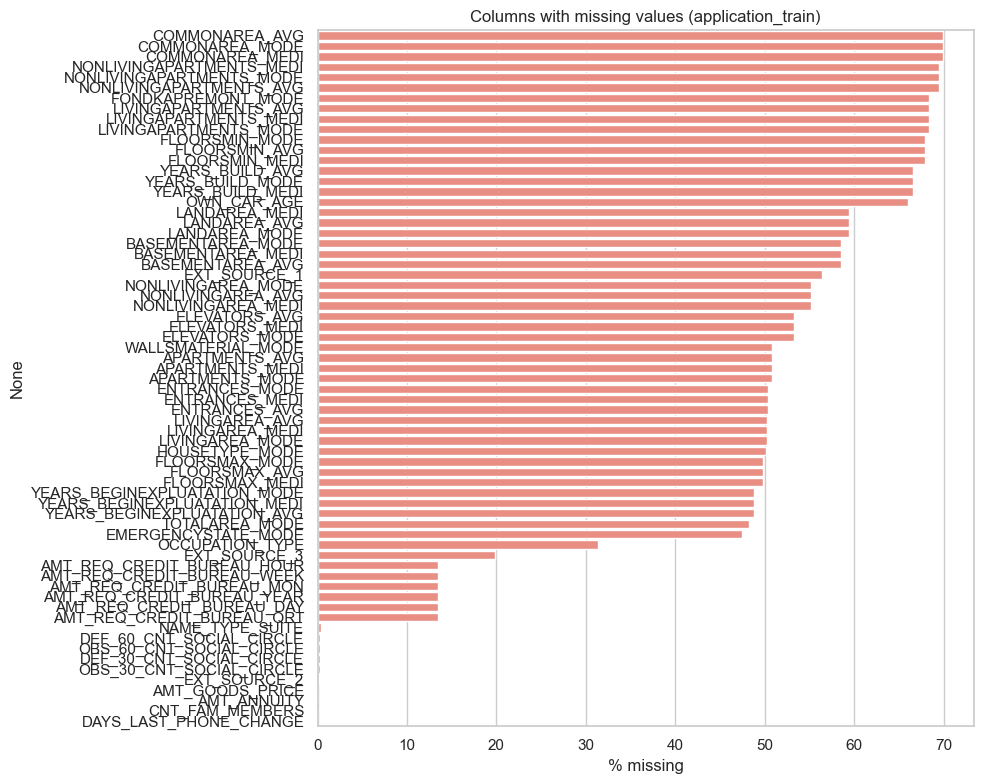

Columns with any missing: 67 / 122


In [3]:
raw_path = RAW_DATA_DIR / "application_train.csv"
df = pd.read_csv(raw_path, low_memory=False)
print("shape:", df.shape)
print("memory_mb:", round(df.memory_usage(deep=True).sum() / 1024**2, 1))

# Working copy we will clean in place / with new columns
clean = df.copy()

miss = (clean.isna().mean() * 100).sort_values(ascending=False)
miss_pos = miss[miss > 0]

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(x=miss_pos.values, y=miss_pos.index, ax=ax, color="salmon")
ax.set_xlabel("% missing")
ax.set_title("Columns with missing values (application_train)")
plt.tight_layout()
plt.show()

print(f"Columns with any missing: {len(miss_pos)} / {clean.shape[1]}")

---
## Feature: `TARGET`

Binary default label. 1 = payment difficulties.


=== TARGET ===
dtype=int64  missing=0 (0.00%)
n_unique=2


count    307511.000000
mean          0.080729
std           0.272419
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           1.000000
Name: TARGET, dtype: float64

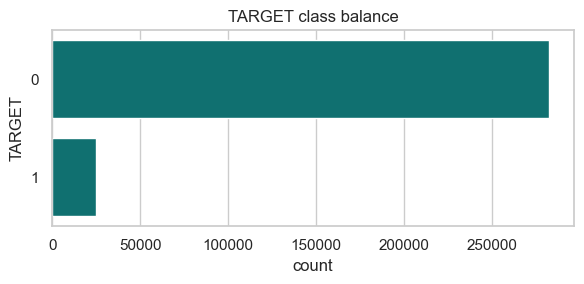

[decision] TARGET: keep as-is (none)


In [4]:
feature_report(clean, "TARGET")
plot_categorical(clean["TARGET"], "TARGET class balance", top_n=None, figsize=(6, 3))

assert set(clean["TARGET"].unique()) <= {0, 1}
assert clean["TARGET"].isna().sum() == 0
record("TARGET", "none", "keep as-is", "binary label, no missing")

---
## Feature: `SK_ID_CURR`

Primary key for the application.

In [5]:
feature_report(clean, "SK_ID_CURR")
n_dup = int(clean["SK_ID_CURR"].duplicated().sum())
print("duplicate keys:", n_dup)
assert n_dup == 0
record("SK_ID_CURR", "none", "keep as-is", "unique primary key")


=== SK_ID_CURR ===
dtype=int64  missing=0 (0.00%)
n_unique=307511


count    307511.000000
mean     278180.518577
std      102790.175348
min      100002.000000
25%      189145.500000
50%      278202.000000
75%      367142.500000
max      456255.000000
Name: SK_ID_CURR, dtype: float64

duplicate keys: 0
[decision] SK_ID_CURR: keep as-is (none)


---
## Feature: `CODE_GENDER`

Expected M/F. Known dirty value: `XNA`.


=== CODE_GENDER ===
dtype=object  missing=0 (0.00%)
n_unique=3


CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

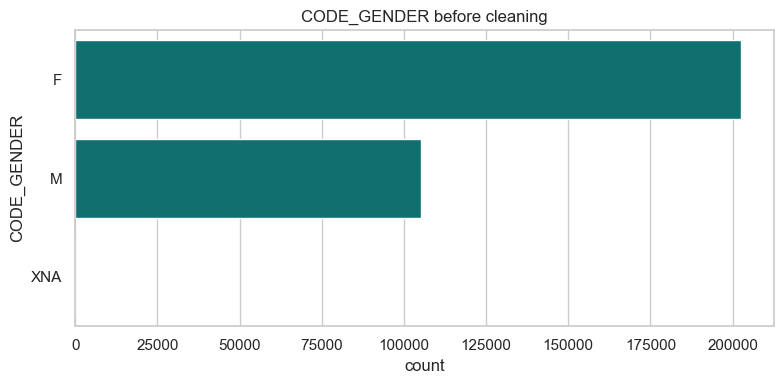

XNA rows: 4
rows removed: 4


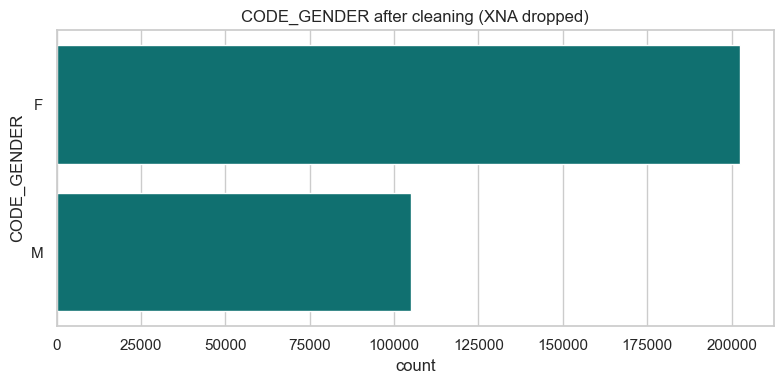

[decision] CODE_GENDER: drop rows where CODE_GENDER == XNA (XNA placeholder)


In [6]:
feature_report(clean, "CODE_GENDER")
plot_categorical(clean["CODE_GENDER"], "CODE_GENDER before cleaning")

n_xna = int((clean["CODE_GENDER"] == "XNA").sum())
print("XNA rows:", n_xna)

# Only a handful of rows -- drop them (not informative, avoids inventing gender)
before_n = len(clean)
clean = clean.loc[clean["CODE_GENDER"] != "XNA"].copy()
print(f"rows removed: {before_n - len(clean)}")

plot_categorical(clean["CODE_GENDER"], "CODE_GENDER after cleaning (XNA dropped)")
record(
    "CODE_GENDER",
    "XNA placeholder",
    "drop rows where CODE_GENDER == XNA",
    f"removed {n_xna} rows",
)

---
## Feature: `NAME_CONTRACT_TYPE`


=== NAME_CONTRACT_TYPE ===
dtype=object  missing=0 (0.00%)
n_unique=2


NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29275
Name: count, dtype: int64

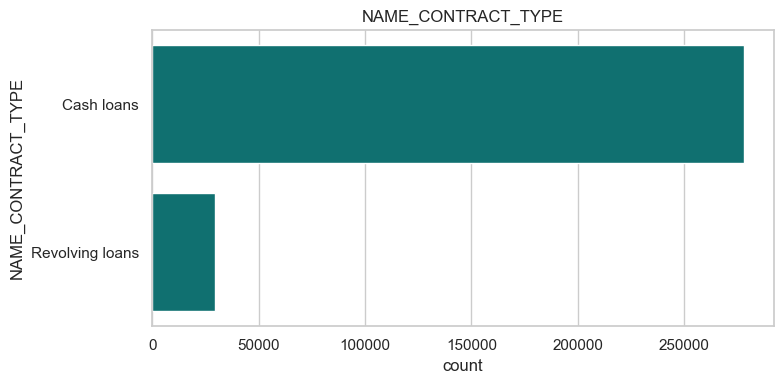

[decision] NAME_CONTRACT_TYPE: keep as-is (none)


In [7]:
feature_report(clean, "NAME_CONTRACT_TYPE")
plot_categorical(clean["NAME_CONTRACT_TYPE"], "NAME_CONTRACT_TYPE")
assert clean["NAME_CONTRACT_TYPE"].isna().sum() == 0
record("NAME_CONTRACT_TYPE", "none", "keep as-is")

---
## Feature: `FLAG_OWN_CAR`


=== FLAG_OWN_CAR ===
dtype=object  missing=0 (0.00%)
n_unique=2


FLAG_OWN_CAR
N    202922
Y    104585
Name: count, dtype: int64

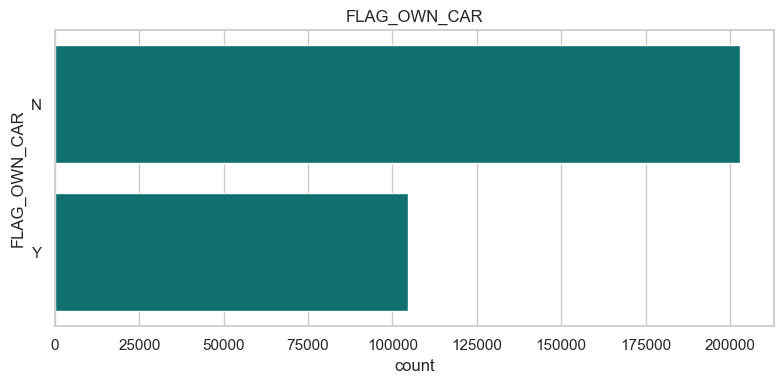

[decision] FLAG_OWN_CAR: keep as-is (none)


In [8]:
feature_report(clean, "FLAG_OWN_CAR")
plot_categorical(clean["FLAG_OWN_CAR"], "FLAG_OWN_CAR")
record("FLAG_OWN_CAR", "none", "keep as-is", "Y/N flag")

---
## Feature: `FLAG_OWN_REALTY`


=== FLAG_OWN_REALTY ===
dtype=object  missing=0 (0.00%)
n_unique=2


FLAG_OWN_REALTY
Y    213308
N     94199
Name: count, dtype: int64

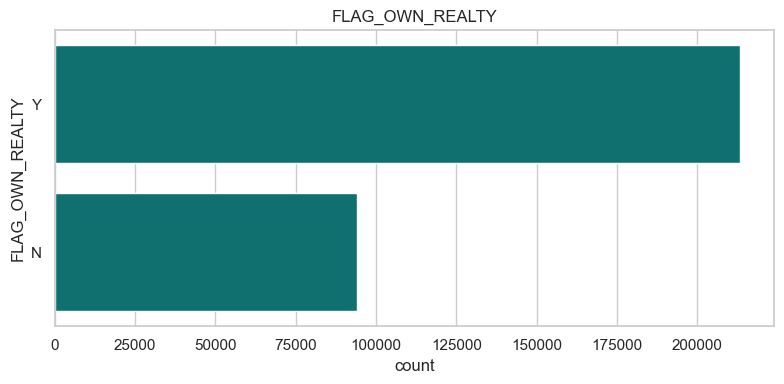

[decision] FLAG_OWN_REALTY: keep as-is (none)


In [9]:
feature_report(clean, "FLAG_OWN_REALTY")
plot_categorical(clean["FLAG_OWN_REALTY"], "FLAG_OWN_REALTY")
record("FLAG_OWN_REALTY", "none", "keep as-is")

---
## Feature: `CNT_CHILDREN`


=== CNT_CHILDREN ===
dtype=int64  missing=0 (0.00%)
n_unique=15


count    307507.000000
mean          0.417047
std           0.722119
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max          19.000000
Name: CNT_CHILDREN, dtype: float64

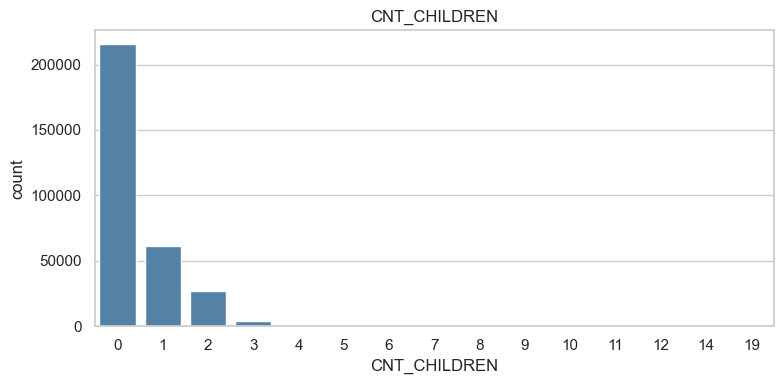

max children: 19
[decision] CNT_CHILDREN: keep raw; optional quantile cap in preprocess stage (right tail / rare large values)


In [10]:
feature_report(clean, "CNT_CHILDREN")
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(x=clean["CNT_CHILDREN"], ax=ax, color="steelblue")
ax.set_title("CNT_CHILDREN")
plt.tight_layout()
plt.show()

print("max children:", clean["CNT_CHILDREN"].max())
# Extreme but possible; keep, cap later in preprocessing if needed
record(
    "CNT_CHILDREN",
    "right tail / rare large values",
    "keep raw; optional quantile cap in preprocess stage",
)

---
## Feature: `AMT_INCOME_TOTAL`

Heavy right tail; check outliers.


=== AMT_INCOME_TOTAL ===
dtype=float64  missing=0 (0.00%)
n_unique=2548


count    3.075070e+05
mean     1.687977e+05
std      2.371246e+05
min      2.565000e+04
25%      1.125000e+05
50%      1.471500e+05
75%      2.025000e+05
max      1.170000e+08
Name: AMT_INCOME_TOTAL, dtype: float64

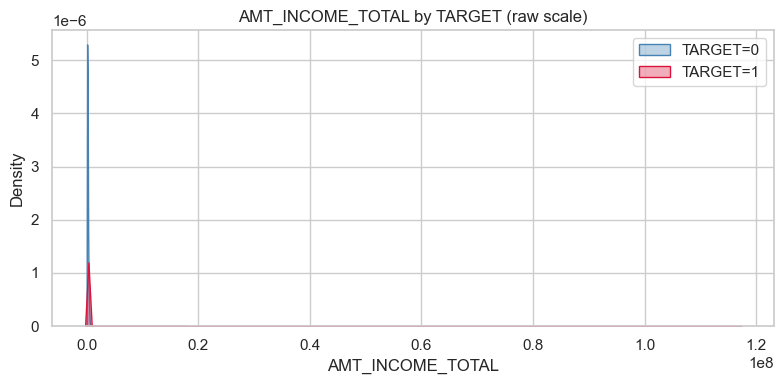

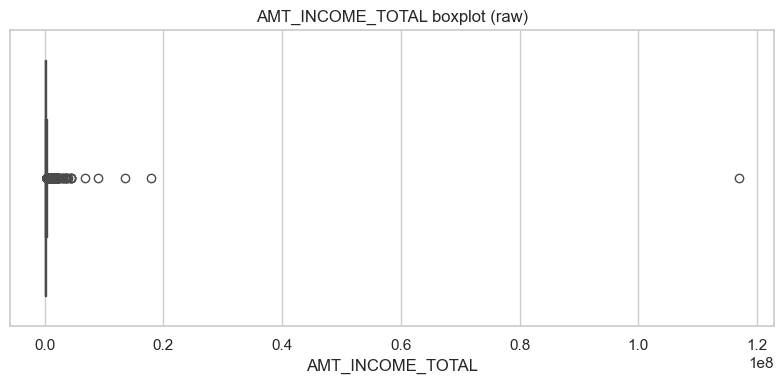

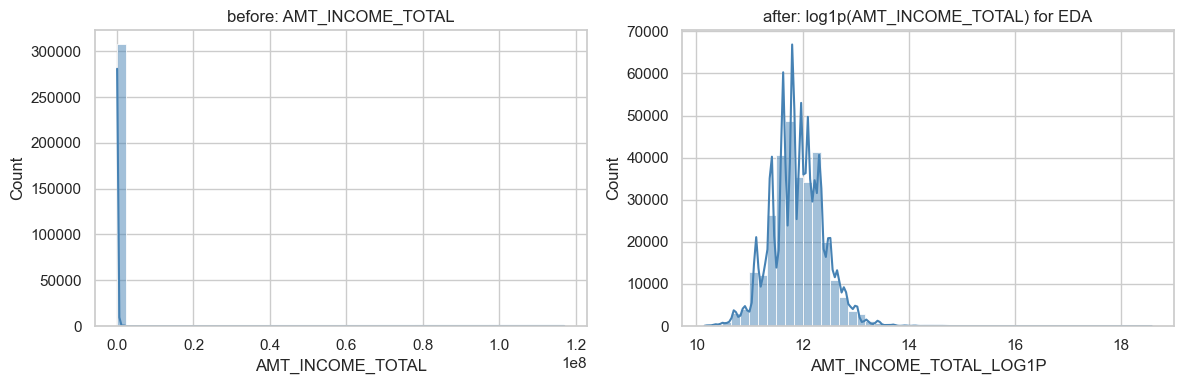

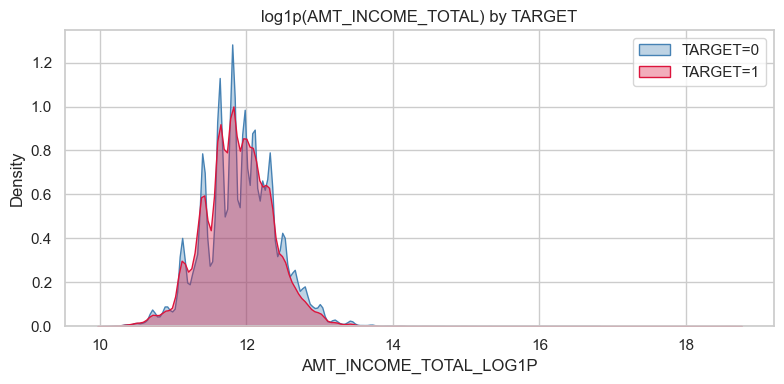

[decision] AMT_INCOME_TOTAL: keep raw for modelling; add log1p view for EDA; cap in preprocess on train only (heavy right skew / extreme incomes)


In [11]:
feature_report(clean, "AMT_INCOME_TOTAL")
plot_numeric_by_target(clean, "AMT_INCOME_TOTAL", "AMT_INCOME_TOTAL by TARGET (raw scale)")

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(x=clean["AMT_INCOME_TOTAL"], ax=ax, color="steelblue")
ax.set_title("AMT_INCOME_TOTAL boxplot (raw)")
plt.tight_layout()
plt.show()

# Log1p view for readability -- do not replace raw yet; store helper column for EDA
clean["AMT_INCOME_TOTAL_LOG1P"] = np.log1p(clean["AMT_INCOME_TOTAL"])
before_after_numeric(
    clean["AMT_INCOME_TOTAL"],
    clean["AMT_INCOME_TOTAL_LOG1P"],
    "before: AMT_INCOME_TOTAL",
    "after: log1p(AMT_INCOME_TOTAL) for EDA",
)
plot_numeric_by_target(
    clean, "AMT_INCOME_TOTAL_LOG1P", "log1p(AMT_INCOME_TOTAL) by TARGET"
)

record(
    "AMT_INCOME_TOTAL",
    "heavy right skew / extreme incomes",
    "keep raw for modelling; add log1p view for EDA; cap in preprocess on train only",
)

---
## Feature: `AMT_CREDIT`


=== AMT_CREDIT ===
dtype=float64  missing=0 (0.00%)
n_unique=5603


count    3.075070e+05
mean     5.990286e+05
std      4.024926e+05
min      4.500000e+04
25%      2.700000e+05
50%      5.135310e+05
75%      8.086500e+05
max      4.050000e+06
Name: AMT_CREDIT, dtype: float64

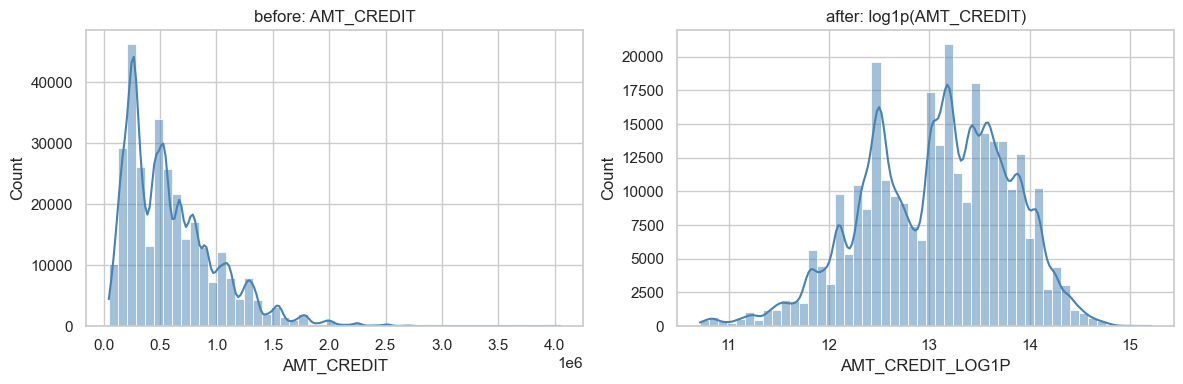

[decision] AMT_CREDIT: keep raw; log1p for EDA / optional transform later (right skew)


In [12]:
feature_report(clean, "AMT_CREDIT")
assert clean["AMT_CREDIT"].isna().sum() == 0
assert (clean["AMT_CREDIT"] > 0).all()

clean["AMT_CREDIT_LOG1P"] = np.log1p(clean["AMT_CREDIT"])
before_after_numeric(
    clean["AMT_CREDIT"],
    clean["AMT_CREDIT_LOG1P"],
    "before: AMT_CREDIT",
    "after: log1p(AMT_CREDIT)",
)
record("AMT_CREDIT", "right skew", "keep raw; log1p for EDA / optional transform later")

---
## Feature: `AMT_ANNUITY`

Has a small number of missing values.


=== AMT_ANNUITY ===
dtype=float64  missing=12 (0.00%)
n_unique=13672


count    307495.000000
mean      27108.666786
std       14493.798379
min        1615.500000
25%       16524.000000
50%       24903.000000
75%       34596.000000
max      258025.500000
Name: AMT_ANNUITY, dtype: float64

missing before: 12


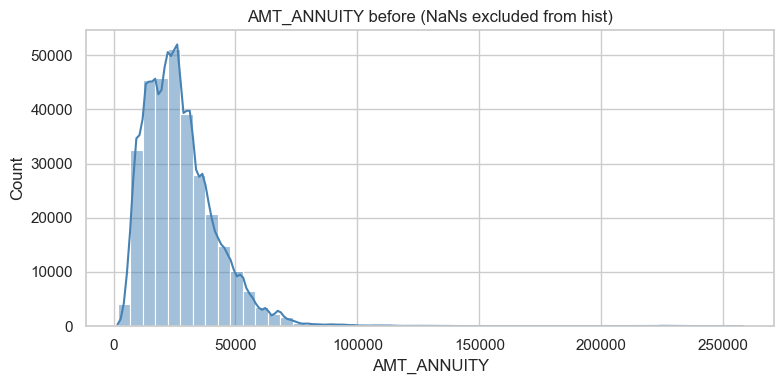

missing indicator rate: 3.9023501904021696e-05
[decision] AMT_ANNUITY: keep NaN + AMT_ANNUITY_MISSING flag; impute in train-only preprocess (12 missing)


In [13]:
feature_report(clean, "AMT_ANNUITY")
n_miss = int(clean["AMT_ANNUITY"].isna().sum())
print("missing before:", n_miss)

fig, ax = plt.subplots(figsize=(8, 4))
plot_numeric(clean["AMT_ANNUITY"], "AMT_ANNUITY before (NaNs excluded from hist)", ax=ax)
plt.tight_layout()
plt.show()

# Missingness is rare; leave NaN and add indicator for preprocess pipeline.
# For cleaned export, keep NaN (imputation must fit on train only later).
clean["AMT_ANNUITY_MISSING"] = clean["AMT_ANNUITY"].isna().astype("int8")

print("missing indicator rate:", clean["AMT_ANNUITY_MISSING"].mean())
record(
    "AMT_ANNUITY",
    f"{n_miss} missing",
    "keep NaN + AMT_ANNUITY_MISSING flag; impute in train-only preprocess",
)

---
## Feature: `AMT_GOODS_PRICE`

Missing for some rows; related to credit amount.


=== AMT_GOODS_PRICE ===
dtype=float64  missing=278 (0.09%)
n_unique=1002


count    3.072290e+05
mean     5.383977e+05
std      3.694472e+05
min      4.050000e+04
25%      2.385000e+05
50%      4.500000e+05
75%      6.795000e+05
max      4.050000e+06
Name: AMT_GOODS_PRICE, dtype: float64

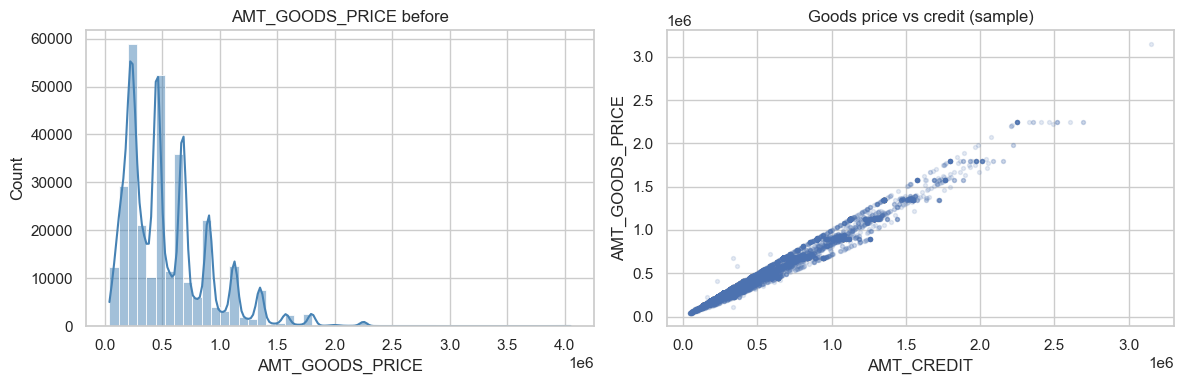

[decision] AMT_GOODS_PRICE: keep NaN + missing flag; impute train-only later (278 missing)


In [14]:
feature_report(clean, "AMT_GOODS_PRICE")
n_miss = int(clean["AMT_GOODS_PRICE"].isna().sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_numeric(clean["AMT_GOODS_PRICE"], "AMT_GOODS_PRICE before", ax=axes[0])
# Relationship to credit when both present
sample = clean.dropna(subset=["AMT_GOODS_PRICE"]).sample(
    min(8000, clean["AMT_GOODS_PRICE"].notna().sum()), random_state=RANDOM_STATE
)
axes[1].scatter(sample["AMT_CREDIT"], sample["AMT_GOODS_PRICE"], alpha=0.15, s=8)
axes[1].set_xlabel("AMT_CREDIT")
axes[1].set_ylabel("AMT_GOODS_PRICE")
axes[1].set_title("Goods price vs credit (sample)")
plt.tight_layout()
plt.show()

clean["AMT_GOODS_PRICE_MISSING"] = clean["AMT_GOODS_PRICE"].isna().astype("int8")
record(
    "AMT_GOODS_PRICE",
    f"{n_miss} missing",
    "keep NaN + missing flag; impute train-only later",
)

---
## Feature: `NAME_TYPE_SUITE`


=== NAME_TYPE_SUITE ===
dtype=object  missing=1,292 (0.42%)
n_unique=7


NAME_TYPE_SUITE
Unaccompanied      248523
Family              40148
Spouse, partner     11370
Children             3267
Other_B              1770
NaN                  1292
Other_A               866
Group of people       271
Name: count, dtype: int64

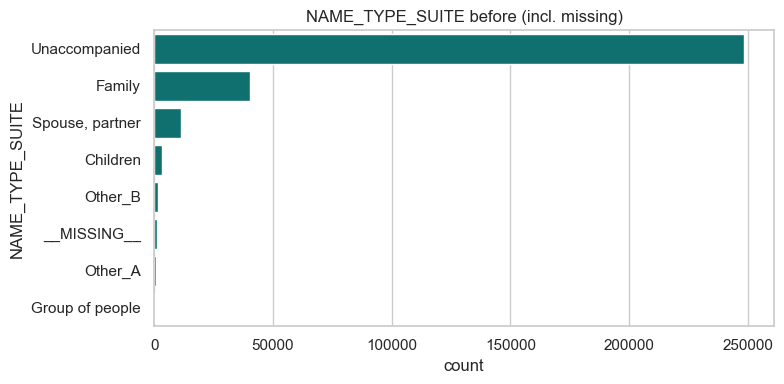

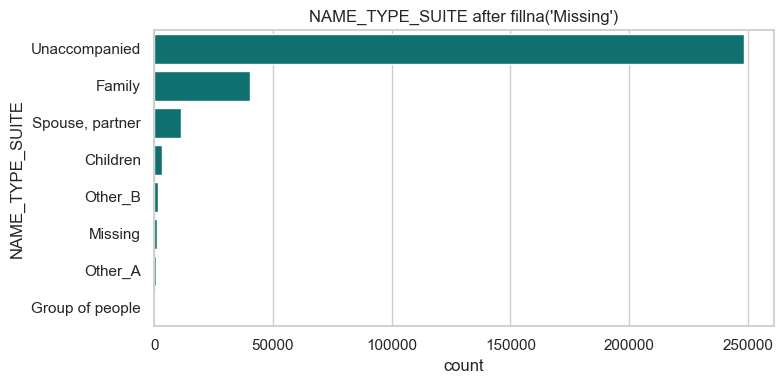

[decision] NAME_TYPE_SUITE: fillna with explicit category 'Missing' (categorical missing)


In [15]:
feature_report(clean, "NAME_TYPE_SUITE")
plot_categorical(clean["NAME_TYPE_SUITE"], "NAME_TYPE_SUITE before (incl. missing)")

clean["NAME_TYPE_SUITE"] = clean["NAME_TYPE_SUITE"].fillna("Missing")
plot_categorical(clean["NAME_TYPE_SUITE"], "NAME_TYPE_SUITE after fillna('Missing')")
record(
    "NAME_TYPE_SUITE",
    "categorical missing",
    "fillna with explicit category 'Missing'",
)

---
## Feature: `NAME_INCOME_TYPE`


=== NAME_INCOME_TYPE ===
dtype=object  missing=0 (0.00%)
n_unique=8


NAME_INCOME_TYPE
Working                 158771
Commercial associate     71616
Pensioner                55362
State servant            21703
Unemployed                  22
Student                     18
Businessman                 10
Maternity leave              5
Name: count, dtype: int64

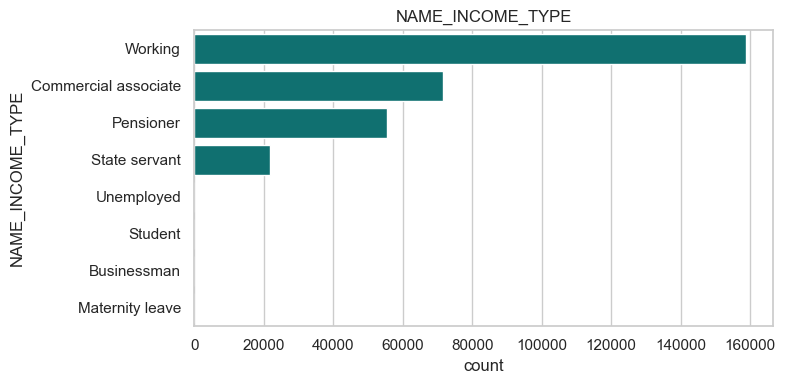

[decision] NAME_INCOME_TYPE: keep as-is (none)


In [16]:
feature_report(clean, "NAME_INCOME_TYPE")
plot_categorical(clean["NAME_INCOME_TYPE"], "NAME_INCOME_TYPE")
record("NAME_INCOME_TYPE", "none", "keep as-is")

---
## Feature: `NAME_EDUCATION_TYPE`


=== NAME_EDUCATION_TYPE ===
dtype=object  missing=0 (0.00%)
n_unique=5


NAME_EDUCATION_TYPE
Secondary / secondary special    218389
Higher education                  74862
Incomplete higher                 10276
Lower secondary                    3816
Academic degree                     164
Name: count, dtype: int64

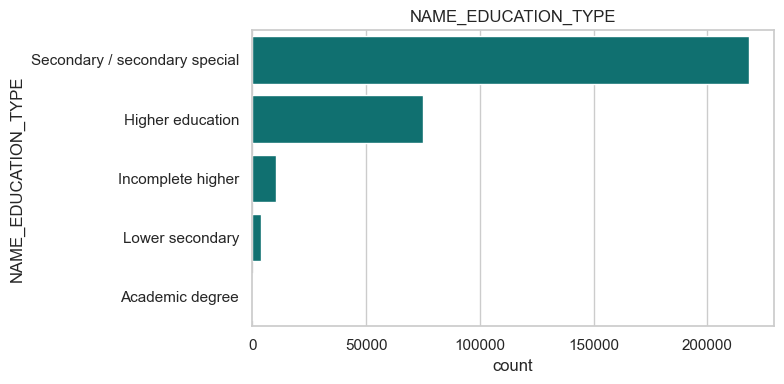

[decision] NAME_EDUCATION_TYPE: keep as-is (none)


In [17]:
feature_report(clean, "NAME_EDUCATION_TYPE")
plot_categorical(clean["NAME_EDUCATION_TYPE"], "NAME_EDUCATION_TYPE")
record("NAME_EDUCATION_TYPE", "none", "keep as-is")

---
## Feature: `NAME_FAMILY_STATUS`

Known dirty value: `Unknown` (very rare).


=== NAME_FAMILY_STATUS ===
dtype=object  missing=0 (0.00%)
n_unique=6


NAME_FAMILY_STATUS
Married                 196429
Single / not married     45444
Civil marriage           29774
Separated                19770
Widow                    16088
Unknown                      2
Name: count, dtype: int64

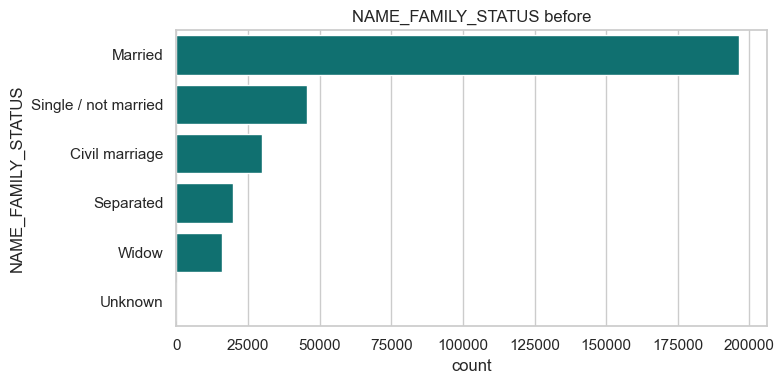

Unknown rows: 2


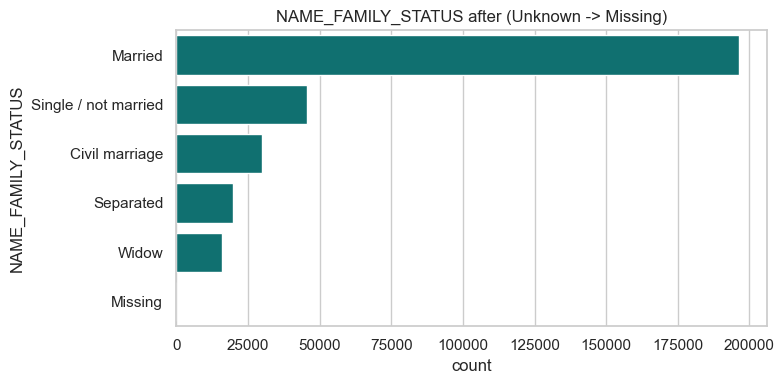

[decision] NAME_FAMILY_STATUS: map Unknown -> Missing (Unknown placeholder)


In [18]:
feature_report(clean, "NAME_FAMILY_STATUS")
plot_categorical(clean["NAME_FAMILY_STATUS"], "NAME_FAMILY_STATUS before")

n_unknown = int((clean["NAME_FAMILY_STATUS"] == "Unknown").sum())
print("Unknown rows:", n_unknown)
clean.loc[clean["NAME_FAMILY_STATUS"] == "Unknown", "NAME_FAMILY_STATUS"] = "Missing"

plot_categorical(clean["NAME_FAMILY_STATUS"], "NAME_FAMILY_STATUS after (Unknown -> Missing)")
record(
    "NAME_FAMILY_STATUS",
    "Unknown placeholder",
    "map Unknown -> Missing",
    f"n={n_unknown}",
)

---
## Feature: `NAME_HOUSING_TYPE`


=== NAME_HOUSING_TYPE ===
dtype=object  missing=0 (0.00%)
n_unique=6


NAME_HOUSING_TYPE
House / apartment      272865
With parents            14840
Municipal apartment     11182
Rented apartment         4881
Office apartment         2617
Co-op apartment          1122
Name: count, dtype: int64

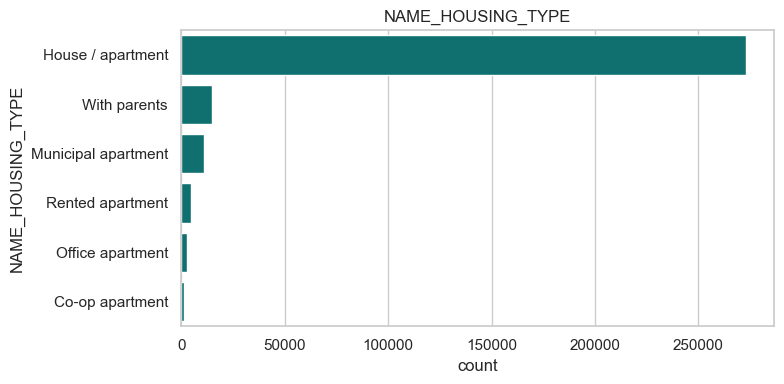

[decision] NAME_HOUSING_TYPE: keep as-is (none)


In [19]:
feature_report(clean, "NAME_HOUSING_TYPE")
plot_categorical(clean["NAME_HOUSING_TYPE"], "NAME_HOUSING_TYPE")
record("NAME_HOUSING_TYPE", "none", "keep as-is")

---
## Feature: `REGION_POPULATION_RELATIVE`


=== REGION_POPULATION_RELATIVE ===
dtype=float64  missing=0 (0.00%)
n_unique=81


count    307507.000000
mean          0.020868
std           0.013831
min           0.000290
25%           0.010006
50%           0.018850
75%           0.028663
max           0.072508
Name: REGION_POPULATION_RELATIVE, dtype: float64

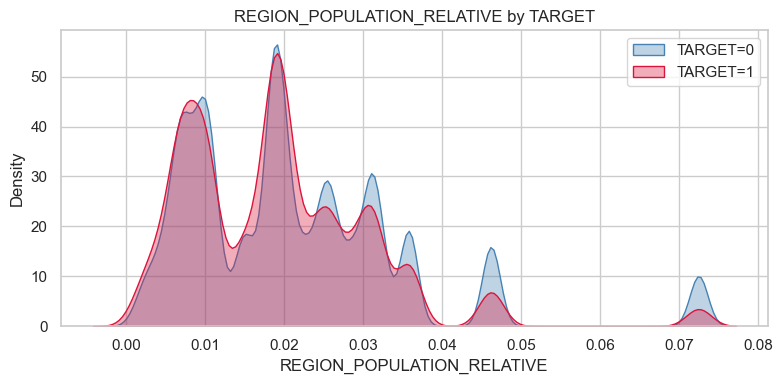

[decision] REGION_POPULATION_RELATIVE: keep as-is (none)


In [20]:
feature_report(clean, "REGION_POPULATION_RELATIVE")
plot_numeric_by_target(
    clean, "REGION_POPULATION_RELATIVE", "REGION_POPULATION_RELATIVE by TARGET"
)
record("REGION_POPULATION_RELATIVE", "none", "keep as-is")

---
## Feature: `DAYS_BIRTH`

Relative day offset (negative). Convert to age in years for interpretability.


=== DAYS_BIRTH ===
dtype=int64  missing=0 (0.00%)
n_unique=17460


count    307507.000000
mean     -16037.027271
std        4363.982424
min      -25229.000000
25%      -19682.000000
50%      -15750.000000
75%      -12413.000000
max       -7489.000000
Name: DAYS_BIRTH, dtype: float64

positive DAYS_BIRTH (unexpected): 0


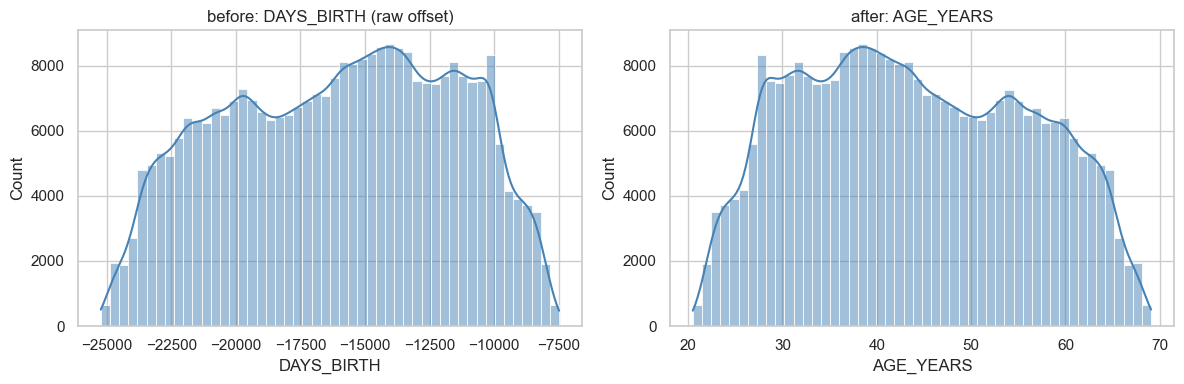

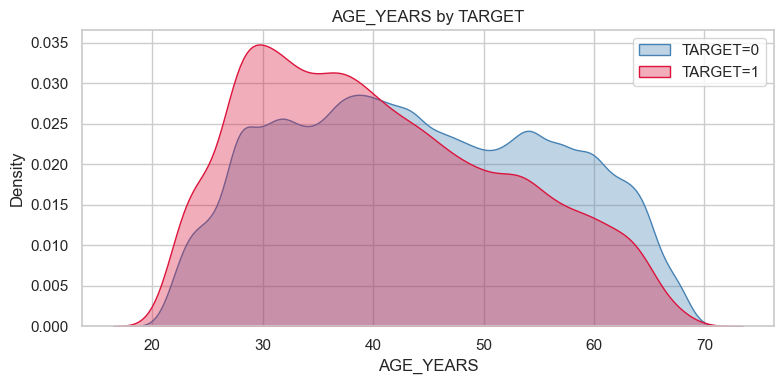

age range: 20.503764544832308 -> 69.07323750855578
[decision] DAYS_BIRTH: derive AGE_YEARS = -DAYS_BIRTH/365.25; keep DAYS_BIRTH too (relative day offset hard to read)


In [21]:
feature_report(clean, "DAYS_BIRTH")
print("positive DAYS_BIRTH (unexpected):", int((clean["DAYS_BIRTH"] > 0).sum()))

before = clean["DAYS_BIRTH"].copy()
clean["AGE_YEARS"] = (-clean["DAYS_BIRTH"] / 365.25).astype("float64")

before_after_numeric(
    before,
    clean["AGE_YEARS"],
    "before: DAYS_BIRTH (raw offset)",
    "after: AGE_YEARS",
)
plot_numeric_by_target(clean, "AGE_YEARS", "AGE_YEARS by TARGET")

print("age range:", clean["AGE_YEARS"].min(), "->", clean["AGE_YEARS"].max())
record(
    "DAYS_BIRTH",
    "relative day offset hard to read",
    "derive AGE_YEARS = -DAYS_BIRTH/365.25; keep DAYS_BIRTH too",
)

---
## Feature: `DAYS_EMPLOYED` (known dirty)

Sentinel `365243` means unemployed / missing employment tenure.


=== DAYS_EMPLOYED ===
dtype=int64  missing=0 (0.00%)
n_unique=12574


count    307507.000000
mean      63815.929208
std      141276.472519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

anomaly count (365243): 55374 (18.01%)


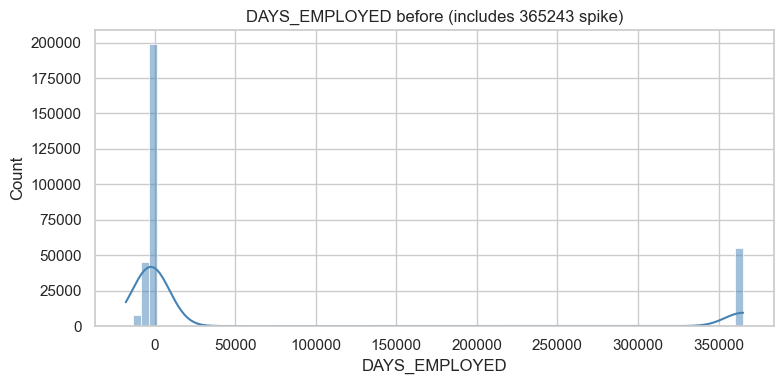

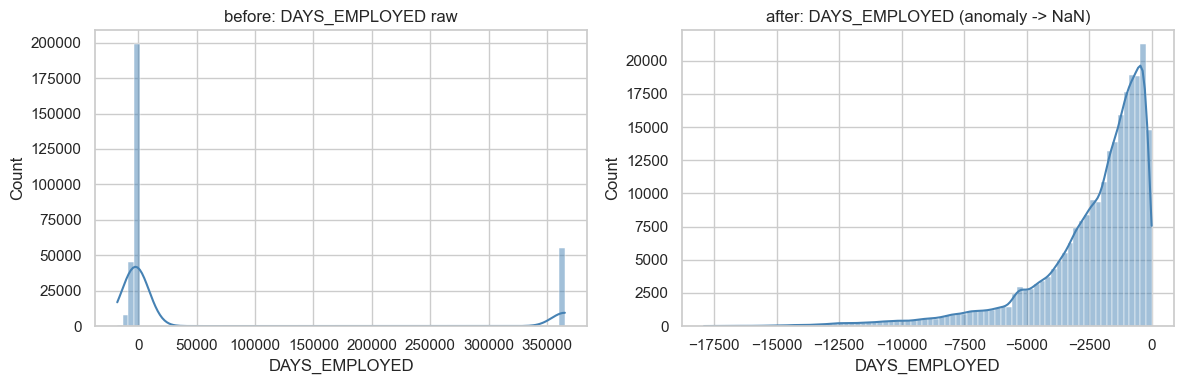

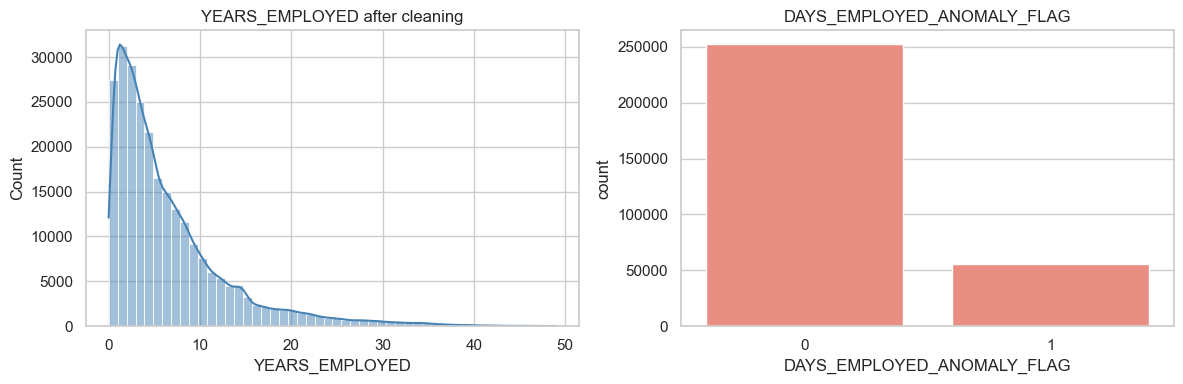

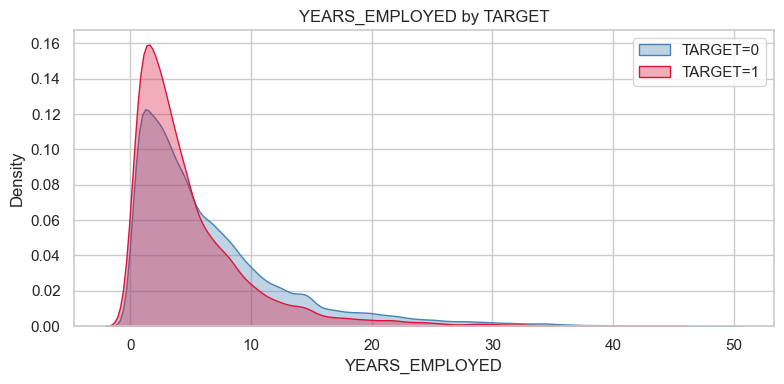

[decision] DAYS_EMPLOYED: set anomaly to NaN; add DAYS_EMPLOYED_ANOMALY_FLAG; derive YEARS_EMPLOYED (sentinel 365243)


In [22]:
feature_report(clean, "DAYS_EMPLOYED")
n_anom = int((clean["DAYS_EMPLOYED"] == DAYS_EMPLOYED_ANOMALY).sum())
print(f"anomaly count ({DAYS_EMPLOYED_ANOMALY}): {n_anom} ({100*n_anom/len(clean):.2f}%)")

before = clean["DAYS_EMPLOYED"].copy()
fig, ax = plt.subplots(figsize=(8, 4))
plot_numeric(before, "DAYS_EMPLOYED before (includes 365243 spike)", bins=80, ax=ax)
plt.tight_layout()
plt.show()

clean["DAYS_EMPLOYED_ANOMALY_FLAG"] = (
    clean["DAYS_EMPLOYED"] == DAYS_EMPLOYED_ANOMALY
).astype("int8")
clean.loc[clean["DAYS_EMPLOYED"] == DAYS_EMPLOYED_ANOMALY, "DAYS_EMPLOYED"] = np.nan
clean["YEARS_EMPLOYED"] = (-clean["DAYS_EMPLOYED"] / 365.25).astype("float64")

before_after_numeric(
    before,
    clean["DAYS_EMPLOYED"],
    "before: DAYS_EMPLOYED raw",
    "after: DAYS_EMPLOYED (anomaly -> NaN)",
    bins=80,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_numeric(clean["YEARS_EMPLOYED"], "YEARS_EMPLOYED after cleaning", ax=axes[0])
sns.countplot(x=clean["DAYS_EMPLOYED_ANOMALY_FLAG"], ax=axes[1], color="salmon")
axes[1].set_title("DAYS_EMPLOYED_ANOMALY_FLAG")
plt.tight_layout()
plt.show()

plot_numeric_by_target(clean, "YEARS_EMPLOYED", "YEARS_EMPLOYED by TARGET")

record(
    "DAYS_EMPLOYED",
    f"sentinel {DAYS_EMPLOYED_ANOMALY}",
    "set anomaly to NaN; add DAYS_EMPLOYED_ANOMALY_FLAG; derive YEARS_EMPLOYED",
    f"n_anom={n_anom}",
)

---
## Feature: `DAYS_REGISTRATION`


=== DAYS_REGISTRATION ===
dtype=float64  missing=0 (0.00%)
n_unique=15688


count    307507.000000
mean      -4986.131376
std        3522.883030
min      -24672.000000
25%       -7479.500000
50%       -4504.000000
75%       -2010.000000
max           0.000000
Name: DAYS_REGISTRATION, dtype: float64

positive values: 0


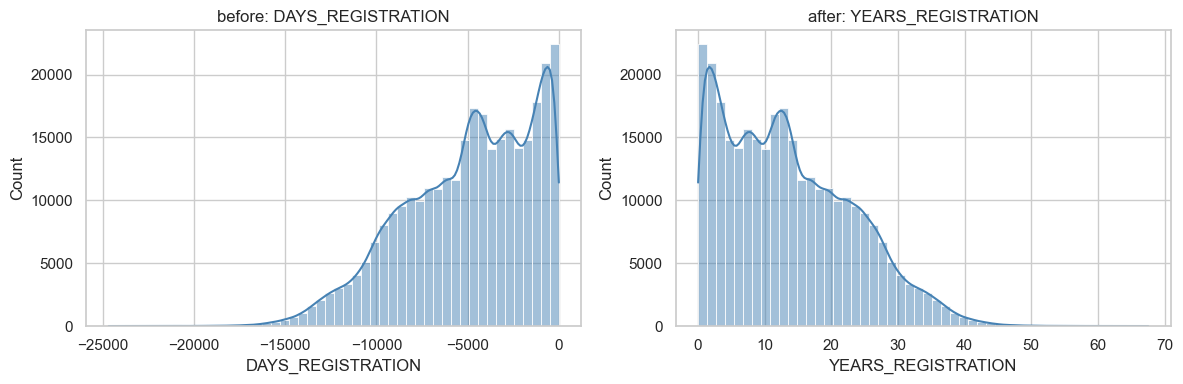

[decision] DAYS_REGISTRATION: derive YEARS_REGISTRATION; keep raw DAYS_REGISTRATION (relative offset)


In [23]:
feature_report(clean, "DAYS_REGISTRATION")
print("positive values:", int((clean["DAYS_REGISTRATION"] > 0).sum()))

before = clean["DAYS_REGISTRATION"].copy()
clean["YEARS_REGISTRATION"] = (-clean["DAYS_REGISTRATION"] / 365.25).astype("float64")
before_after_numeric(
    before,
    clean["YEARS_REGISTRATION"],
    "before: DAYS_REGISTRATION",
    "after: YEARS_REGISTRATION",
)
record(
    "DAYS_REGISTRATION",
    "relative offset",
    "derive YEARS_REGISTRATION; keep raw DAYS_REGISTRATION",
)

---
## Feature: `DAYS_ID_PUBLISH`


=== DAYS_ID_PUBLISH ===
dtype=int64  missing=0 (0.00%)
n_unique=6168


count    307507.000000
mean      -2994.201670
std        1509.454566
min       -7197.000000
25%       -4299.000000
50%       -3254.000000
75%       -1720.000000
max           0.000000
Name: DAYS_ID_PUBLISH, dtype: float64

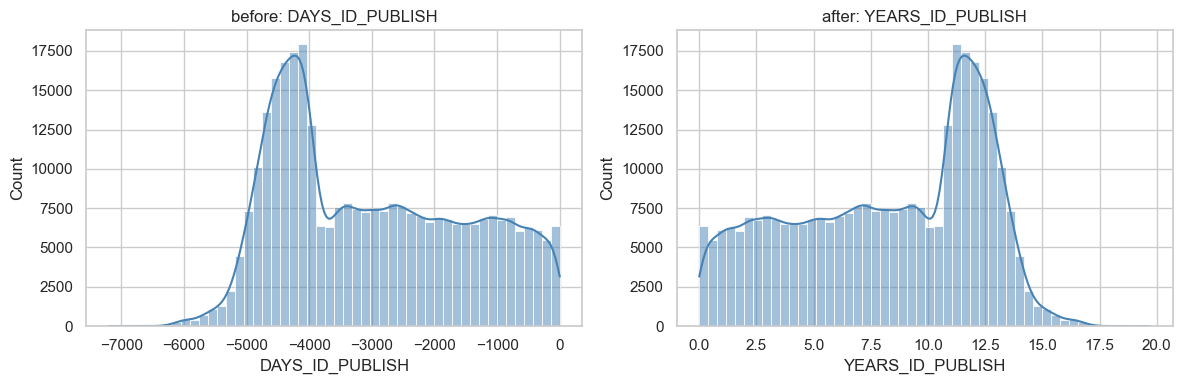

[decision] DAYS_ID_PUBLISH: derive YEARS_ID_PUBLISH (relative offset)


In [24]:
feature_report(clean, "DAYS_ID_PUBLISH")
before = clean["DAYS_ID_PUBLISH"].copy()
clean["YEARS_ID_PUBLISH"] = (-clean["DAYS_ID_PUBLISH"] / 365.25).astype("float64")
before_after_numeric(
    before,
    clean["YEARS_ID_PUBLISH"],
    "before: DAYS_ID_PUBLISH",
    "after: YEARS_ID_PUBLISH",
)
record("DAYS_ID_PUBLISH", "relative offset", "derive YEARS_ID_PUBLISH")

---
## Feature: `OWN_CAR_AGE`

Missing mostly when applicant has no car -- structurally missing, not random.


=== OWN_CAR_AGE ===
dtype=float64  missing=202,927 (65.99%)
n_unique=62


count    104580.000000
mean         12.061121
std          11.944919
min           0.000000
25%           5.000000
50%           9.000000
75%          15.000000
max          91.000000
Name: OWN_CAR_AGE, dtype: float64

,OWN_CAR_AGE_present,OWN_CAR_AGE_missing
FLAG_OWN_CAR,,
N,0,202922
Y,104580,5


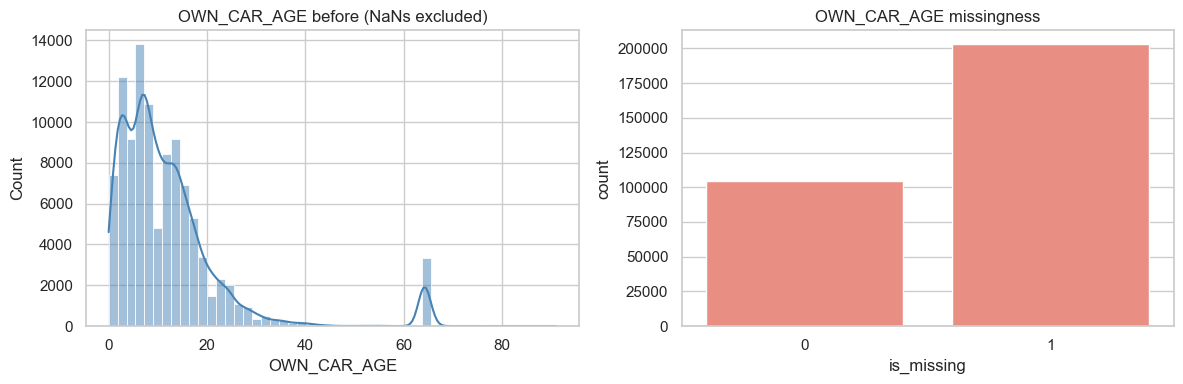

FLAG_OWN_CAR among OWN_CAR_AGE missing:
 FLAG_OWN_CAR
N    0.999975
Y    0.000025
Name: proportion, dtype: float64
[decision] OWN_CAR_AGE: keep NaN + OWN_CAR_AGE_MISSING; do not impute age for non-owners (structural missing when no car)


In [25]:
feature_report(clean, "OWN_CAR_AGE")

ct = pd.crosstab(clean["FLAG_OWN_CAR"], clean["OWN_CAR_AGE"].isna())
ct.columns = ["OWN_CAR_AGE_present", "OWN_CAR_AGE_missing"]
display(ct)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_numeric(clean["OWN_CAR_AGE"], "OWN_CAR_AGE before (NaNs excluded)", ax=axes[0])
sns.countplot(
    x=clean["OWN_CAR_AGE"].isna().astype(int),
    ax=axes[1],
    color="salmon",
)
axes[1].set_xlabel("is_missing")
axes[1].set_title("OWN_CAR_AGE missingness")
plt.tight_layout()
plt.show()

# Sanity: almost all missing should be FLAG_OWN_CAR == N
share = clean.loc[clean["OWN_CAR_AGE"].isna(), "FLAG_OWN_CAR"].value_counts(normalize=True)
print("FLAG_OWN_CAR among OWN_CAR_AGE missing:\n", share)

clean["OWN_CAR_AGE_MISSING"] = clean["OWN_CAR_AGE"].isna().astype("int8")
# Leave NaN for no-car; do not invent car age
record(
    "OWN_CAR_AGE",
    "structural missing when no car",
    "keep NaN + OWN_CAR_AGE_MISSING; do not impute age for non-owners",
)

---
## Feature: `OCCUPATION_TYPE`


=== OCCUPATION_TYPE ===
dtype=object  missing=96,389 (31.35%)
n_unique=18


OCCUPATION_TYPE
NaN                      96389
Laborers                 55186
Sales staff              32102
Core staff               27569
Managers                 21371
Drivers                  18603
High skill tech staff    11380
Accountants               9813
Medicine staff            8537
Security staff            6721
Cooking staff             5946
Cleaning staff            4653
Private service staff     2652
Low-skill Laborers        2092
Waiters/barmen staff      1348
Name: count, dtype: int64

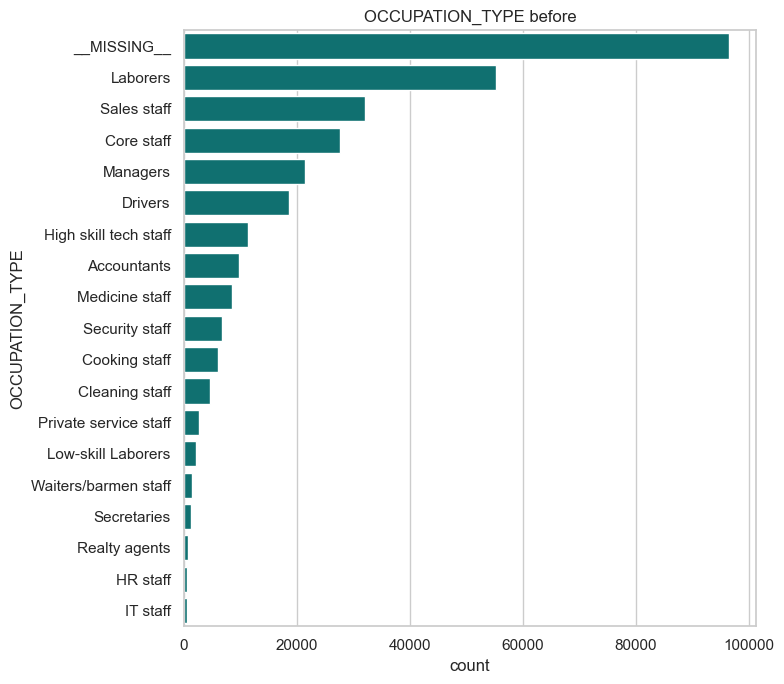

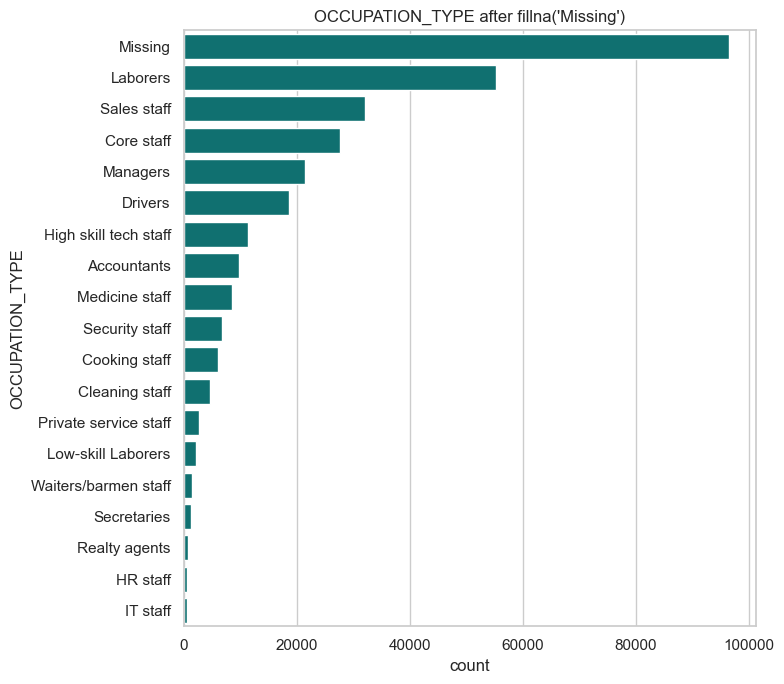

[decision] OCCUPATION_TYPE: fillna 'Missing' (high missing)


In [26]:
feature_report(clean, "OCCUPATION_TYPE")
plot_categorical(clean["OCCUPATION_TYPE"], "OCCUPATION_TYPE before", top_n=25, figsize=(8, 7))

clean["OCCUPATION_TYPE"] = clean["OCCUPATION_TYPE"].fillna("Missing")
plot_categorical(clean["OCCUPATION_TYPE"], "OCCUPATION_TYPE after fillna('Missing')", top_n=25, figsize=(8, 7))
record("OCCUPATION_TYPE", "high missing", "fillna 'Missing'")

---
## Feature: `CNT_FAM_MEMBERS`


=== CNT_FAM_MEMBERS ===
dtype=float64  missing=2 (0.00%)
n_unique=17


count    307505.000000
mean          2.152658
std           0.910680
min           1.000000
25%           2.000000
50%           2.000000
75%           3.000000
max          20.000000
Name: CNT_FAM_MEMBERS, dtype: float64

missing: 2


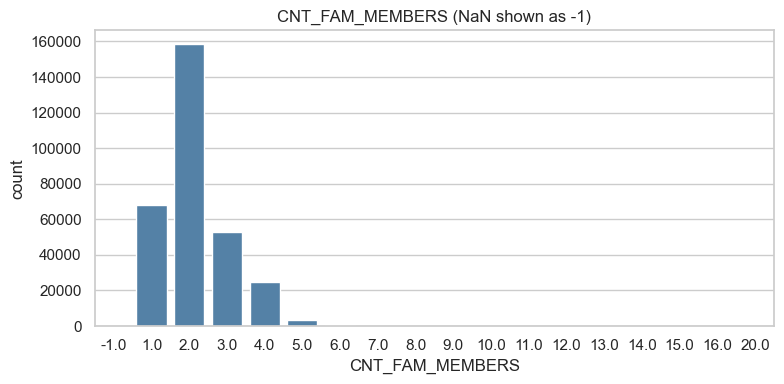

rows with CNT_FAM_MEMBERS < CNT_CHILDREN: 0
[decision] CNT_FAM_MEMBERS: keep NaN + missing flag; note inconsistencies, do not force-fix (2 missing; 0 inconsistent vs children)


In [27]:
feature_report(clean, "CNT_FAM_MEMBERS")
n_miss = int(clean["CNT_FAM_MEMBERS"].isna().sum())
print("missing:", n_miss)

fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(x=clean["CNT_FAM_MEMBERS"].fillna(-1), ax=ax, color="steelblue")
ax.set_title("CNT_FAM_MEMBERS (NaN shown as -1)")
plt.tight_layout()
plt.show()

# Consistency with children: family members should be >= children + 1 typically
tmp = clean.dropna(subset=["CNT_FAM_MEMBERS"])
inconsistent = int((tmp["CNT_FAM_MEMBERS"] < tmp["CNT_CHILDREN"]).sum())
print("rows with CNT_FAM_MEMBERS < CNT_CHILDREN:", inconsistent)

clean["CNT_FAM_MEMBERS_MISSING"] = clean["CNT_FAM_MEMBERS"].isna().astype("int8")
record(
    "CNT_FAM_MEMBERS",
    f"{n_miss} missing; {inconsistent} inconsistent vs children",
    "keep NaN + missing flag; note inconsistencies, do not force-fix",
)

---
## Feature: `ORGANIZATION_TYPE`

Contains `XNA` for unemployed / unknown org.


=== ORGANIZATION_TYPE ===
dtype=object  missing=0 (0.00%)
n_unique=58


ORGANIZATION_TYPE
Business Entity Type 3    67992
XNA                       55374
Self-employed             38412
Other                     16683
Medicine                  11192
Business Entity Type 2    10553
Government                10404
School                     8893
Trade: type 7              7831
Kindergarten               6879
Construction               6721
Business Entity Type 1     5983
Transport: type 4          5398
Trade: type 3              3492
Industry: type 9           3368
Name: count, dtype: int64

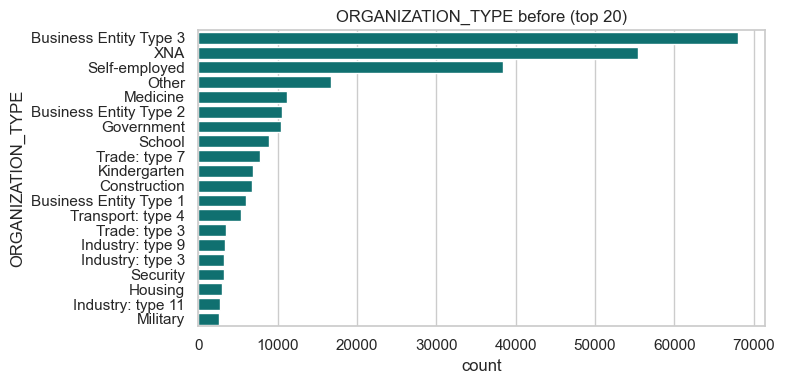

XNA: 55374
XNA and employment anomaly overlap: 55374


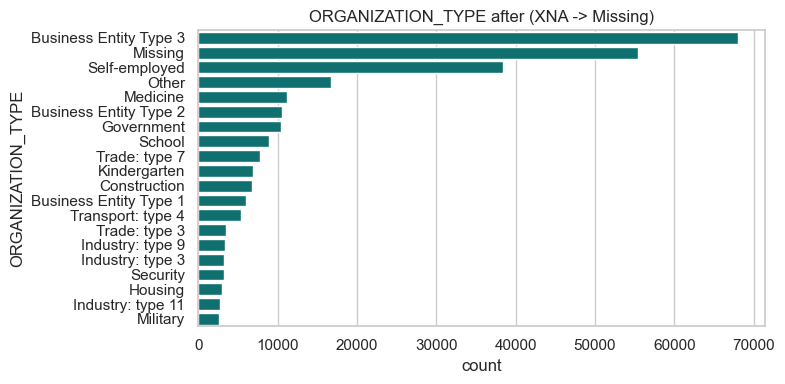

[decision] ORGANIZATION_TYPE: map XNA -> Missing (XNA placeholder)


In [28]:
feature_report(clean, "ORGANIZATION_TYPE")
plot_categorical(clean["ORGANIZATION_TYPE"], "ORGANIZATION_TYPE before (top 20)", top_n=20)

n_xna = int((clean["ORGANIZATION_TYPE"] == "XNA").sum())
print("XNA:", n_xna)

# Align with employment anomaly: XNA often matches unemployed sentinel
overlap = int(
    ((clean["ORGANIZATION_TYPE"] == "XNA") & (clean["DAYS_EMPLOYED_ANOMALY_FLAG"] == 1)).sum()
)
print("XNA and employment anomaly overlap:", overlap)

clean["ORGANIZATION_TYPE"] = clean["ORGANIZATION_TYPE"].replace({"XNA": "Missing"})
plot_categorical(clean["ORGANIZATION_TYPE"], "ORGANIZATION_TYPE after (XNA -> Missing)", top_n=20)
record(
    "ORGANIZATION_TYPE",
    "XNA placeholder",
    "map XNA -> Missing",
    f"n_xna={n_xna}, overlap_with_emp_anomaly={overlap}",
)

---
## Features: `EXT_SOURCE_1`, `EXT_SOURCE_2`, `EXT_SOURCE_3`

External score features; high missing on EXT_SOURCE_1. Inspect one at a time.


=== EXT_SOURCE_1 ===
dtype=float64  missing=173,376 (56.38%)
n_unique=114583


count    134131.000000
mean          0.502129
std           0.211063
min           0.014568
25%           0.334007
50%           0.505998
75%           0.675057
max           0.962693
Name: EXT_SOURCE_1, dtype: float64

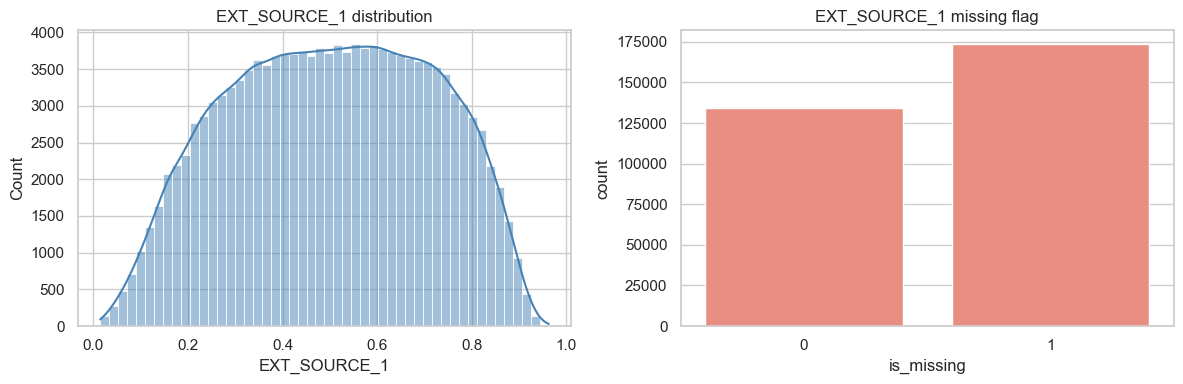

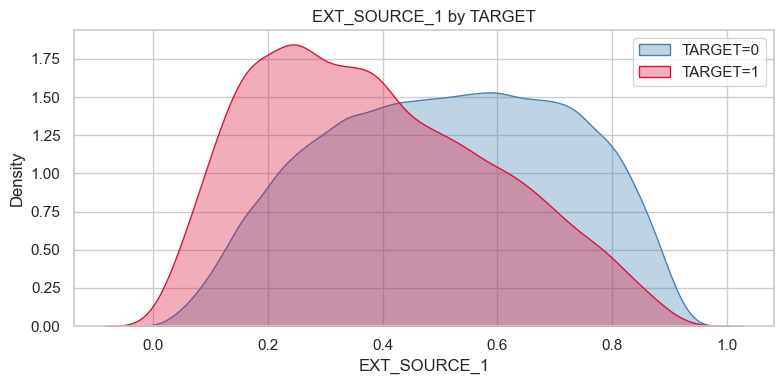

[decision] EXT_SOURCE_1: keep NaN + EXT_SOURCE_1_MISSING; impute train-only later (173376 missing (56.4%))

=== EXT_SOURCE_2 ===
dtype=float64  missing=660 (0.21%)
n_unique=119830


count    3.068470e+05
mean     5.143918e-01
std      1.910603e-01
min      8.173617e-08
25%      3.924574e-01
50%      5.659614e-01
75%      6.636171e-01
max      8.549997e-01
Name: EXT_SOURCE_2, dtype: float64

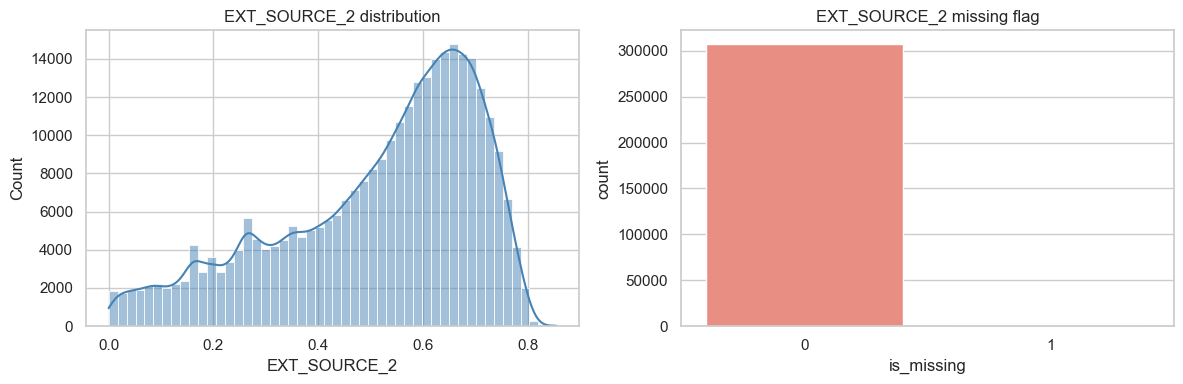

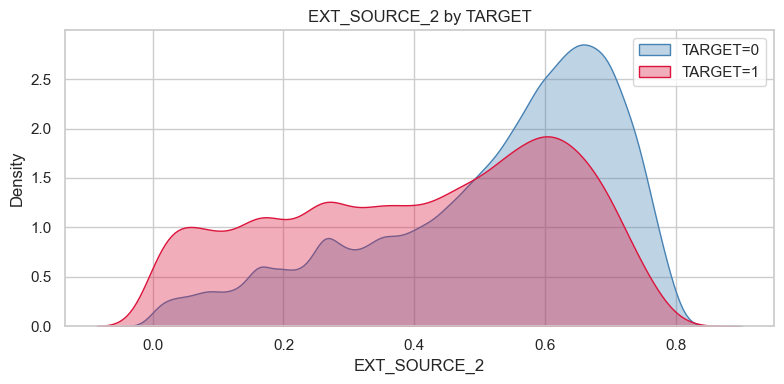

[decision] EXT_SOURCE_2: keep NaN + EXT_SOURCE_2_MISSING; impute train-only later (660 missing (0.2%))

=== EXT_SOURCE_3 ===
dtype=float64  missing=60,965 (19.83%)
n_unique=814


count    246542.000000
mean          0.510856
std           0.194843
min           0.000527
25%           0.370650
50%           0.535276
75%           0.669057
max           0.896010
Name: EXT_SOURCE_3, dtype: float64

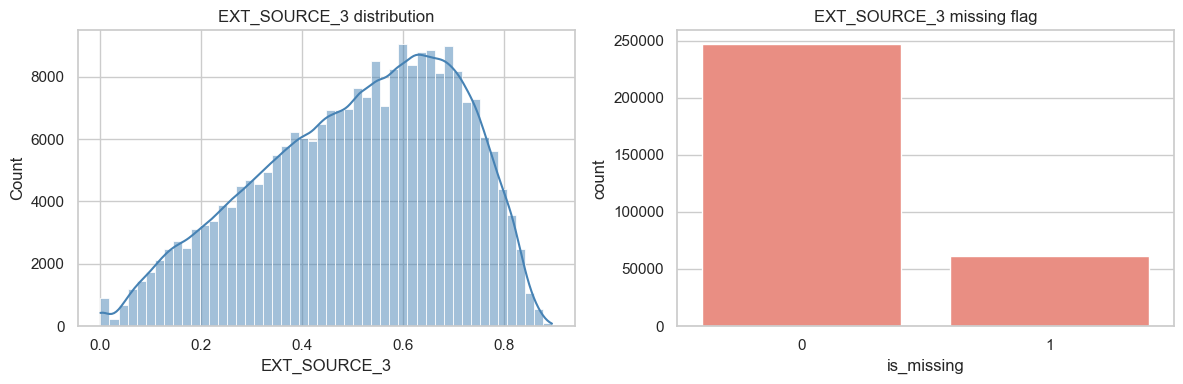

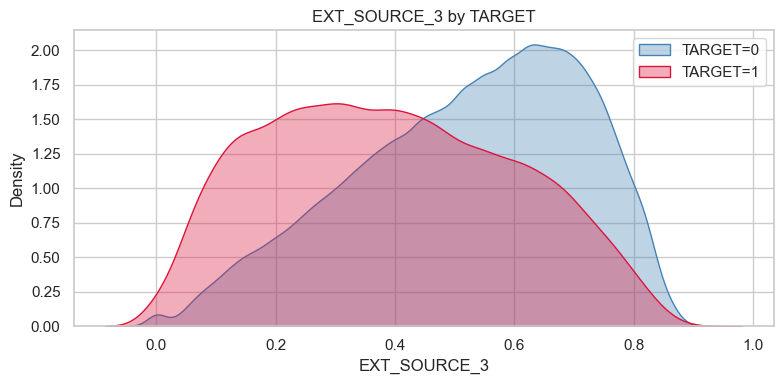

[decision] EXT_SOURCE_3: keep NaN + EXT_SOURCE_3_MISSING; impute train-only later (60965 missing (19.8%))


In [29]:
for col in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
    feature_report(clean, col)
    n_miss = int(clean[col].isna().sum())
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    plot_numeric(clean[col], f"{col} distribution", ax=axes[0])
    sns.countplot(x=clean[col].isna().astype(int), ax=axes[1], color="salmon")
    axes[1].set_title(f"{col} missing flag")
    axes[1].set_xlabel("is_missing")
    plt.tight_layout()
    plt.show()
    plot_numeric_by_target(clean, col, f"{col} by TARGET")

    miss_col = f"{col}_MISSING"
    clean[miss_col] = clean[col].isna().astype("int8")
    record(
        col,
        f"{n_miss} missing ({100*n_miss/len(clean):.1f}%)",
        f"keep NaN + {miss_col}; impute train-only later",
    )

---
## Features: bureau enquiry counts `AMT_REQ_CREDIT_BUREAU_*`

Often missing together. Inspect each; add missing flags; leave NaN for train-only impute.


=== AMT_REQ_CREDIT_BUREAU_HOUR ===
dtype=float64  missing=41,519 (13.50%)
n_unique=5


count    265988.000000
mean          0.006403
std           0.083850
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           4.000000
Name: AMT_REQ_CREDIT_BUREAU_HOUR, dtype: float64

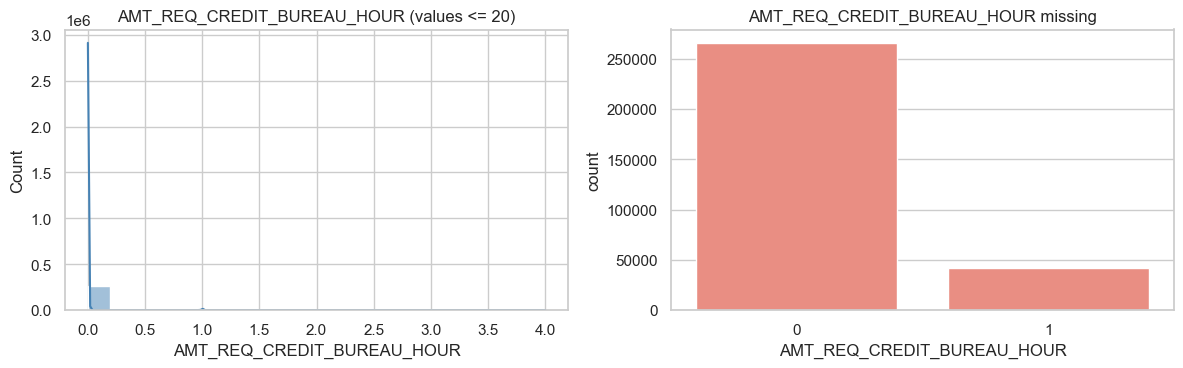

[decision] AMT_REQ_CREDIT_BUREAU_HOUR: keep NaN + AMT_REQ_CREDIT_BUREAU_HOUR_MISSING (missing block with other bureau reqs)

=== AMT_REQ_CREDIT_BUREAU_DAY ===
dtype=float64  missing=41,519 (13.50%)
n_unique=9


count    265988.000000
mean          0.007000
std           0.110758
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           9.000000
Name: AMT_REQ_CREDIT_BUREAU_DAY, dtype: float64

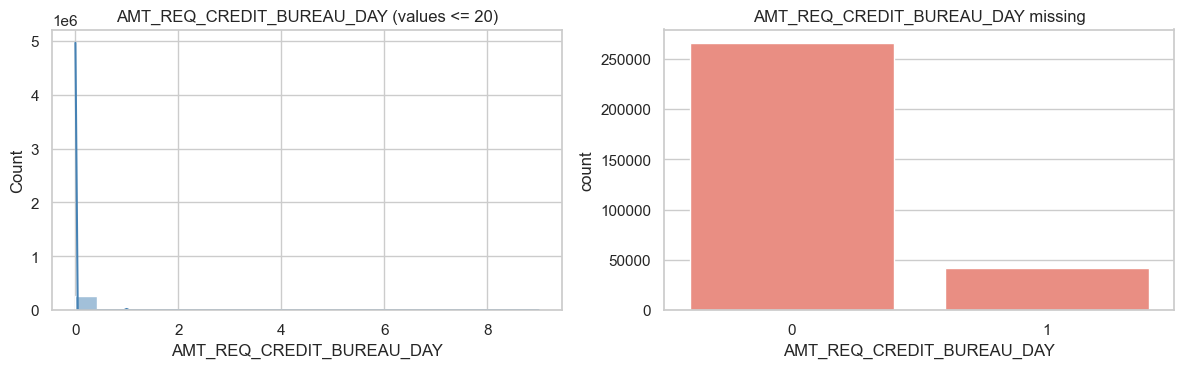

[decision] AMT_REQ_CREDIT_BUREAU_DAY: keep NaN + AMT_REQ_CREDIT_BUREAU_DAY_MISSING (missing block with other bureau reqs)

=== AMT_REQ_CREDIT_BUREAU_WEEK ===
dtype=float64  missing=41,519 (13.50%)
n_unique=9


count    265988.000000
mean          0.034362
std           0.204686
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           8.000000
Name: AMT_REQ_CREDIT_BUREAU_WEEK, dtype: float64

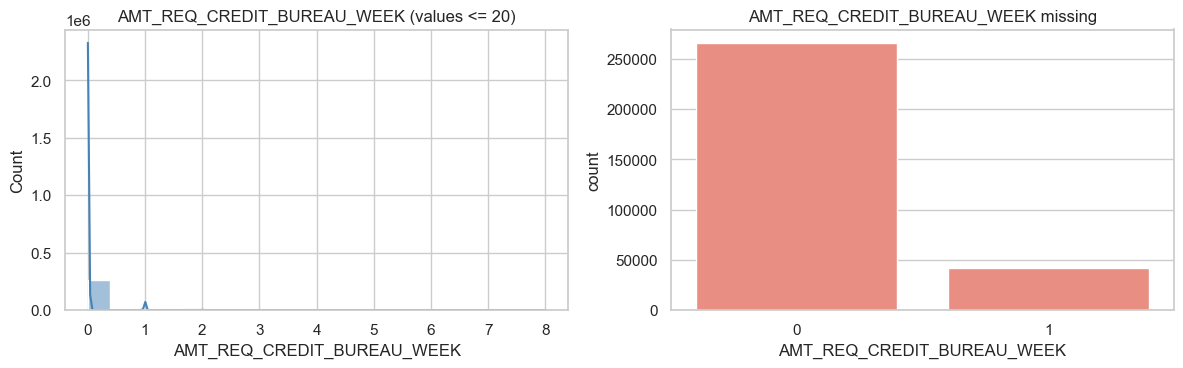

[decision] AMT_REQ_CREDIT_BUREAU_WEEK: keep NaN + AMT_REQ_CREDIT_BUREAU_WEEK_MISSING (missing block with other bureau reqs)

=== AMT_REQ_CREDIT_BUREAU_MON ===
dtype=float64  missing=41,519 (13.50%)
n_unique=24


count    265988.000000
mean          0.267388
std           0.915994
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          27.000000
Name: AMT_REQ_CREDIT_BUREAU_MON, dtype: float64

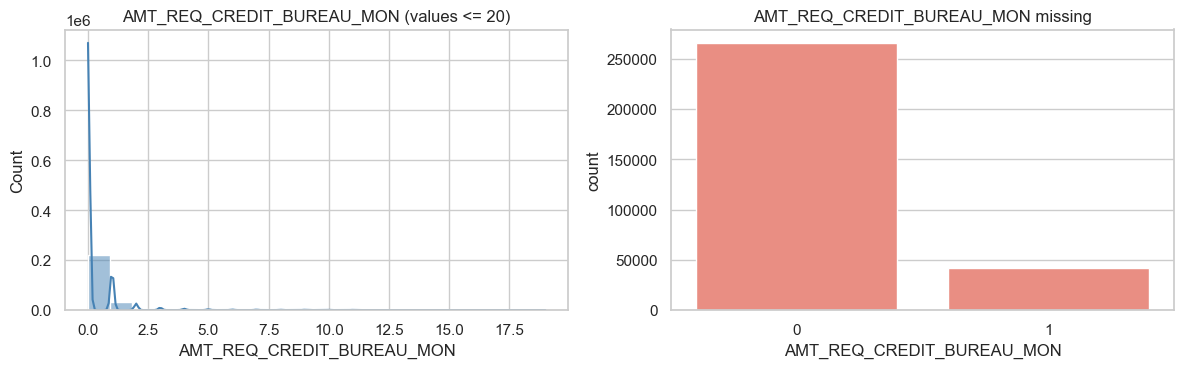

[decision] AMT_REQ_CREDIT_BUREAU_MON: keep NaN + AMT_REQ_CREDIT_BUREAU_MON_MISSING (missing block with other bureau reqs)

=== AMT_REQ_CREDIT_BUREAU_QRT ===
dtype=float64  missing=41,519 (13.50%)
n_unique=11


count    265988.000000
mean          0.265474
std           0.794060
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max         261.000000
Name: AMT_REQ_CREDIT_BUREAU_QRT, dtype: float64

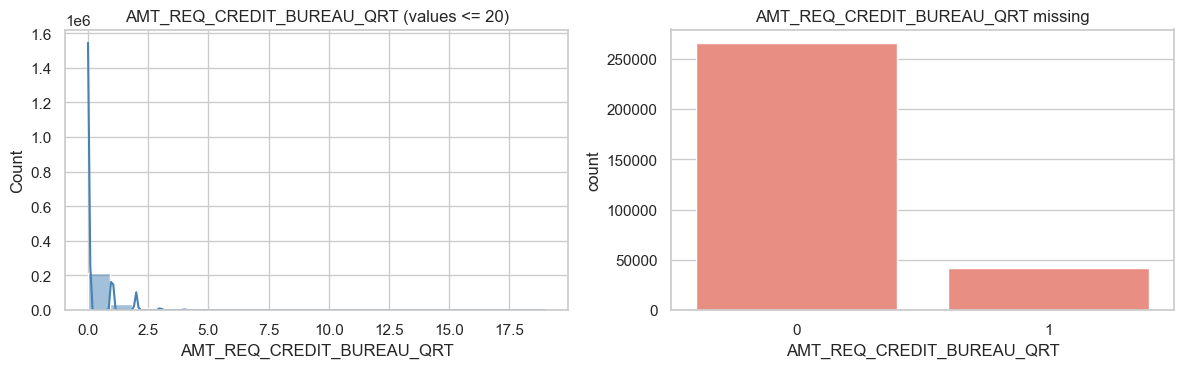

[decision] AMT_REQ_CREDIT_BUREAU_QRT: keep NaN + AMT_REQ_CREDIT_BUREAU_QRT_MISSING (missing block with other bureau reqs)

=== AMT_REQ_CREDIT_BUREAU_YEAR ===
dtype=float64  missing=41,519 (13.50%)
n_unique=25


count    265988.000000
mean          1.899950
std           1.869286
min           0.000000
25%           0.000000
50%           1.000000
75%           3.000000
max          25.000000
Name: AMT_REQ_CREDIT_BUREAU_YEAR, dtype: float64

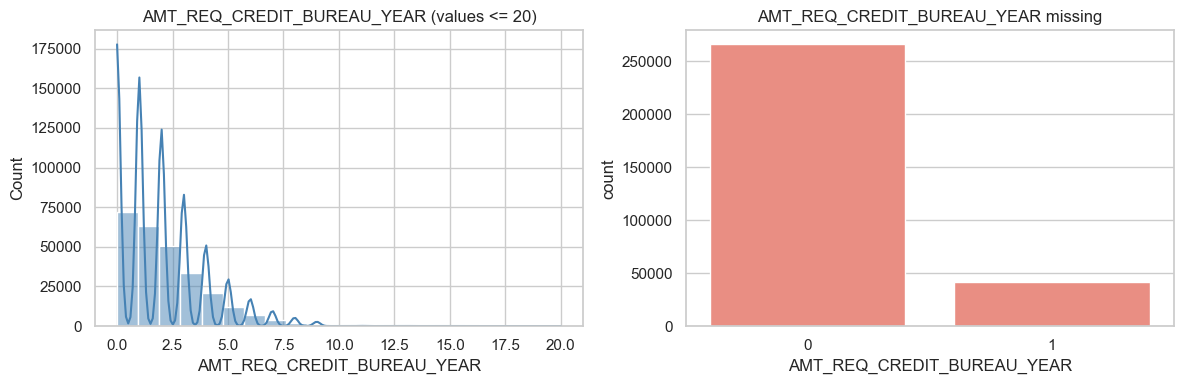

[decision] AMT_REQ_CREDIT_BUREAU_YEAR: keep NaN + AMT_REQ_CREDIT_BUREAU_YEAR_MISSING (missing block with other bureau reqs)


In [30]:
bureau_req_cols = [
    "AMT_REQ_CREDIT_BUREAU_HOUR",
    "AMT_REQ_CREDIT_BUREAU_DAY",
    "AMT_REQ_CREDIT_BUREAU_WEEK",
    "AMT_REQ_CREDIT_BUREAU_MON",
    "AMT_REQ_CREDIT_BUREAU_QRT",
    "AMT_REQ_CREDIT_BUREAU_YEAR",
]

for col in bureau_req_cols:
    feature_report(clean, col)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    # Most mass near 0 -- clip x for readability in hist
    s = clean[col]
    plot_numeric(s[s.notna() & (s <= 20)], f"{col} (values <= 20)", bins=21, ax=axes[0])
    sns.countplot(x=s.isna().astype(int), ax=axes[1], color="salmon")
    axes[1].set_title(f"{col} missing")
    plt.tight_layout()
    plt.show()
    clean[f"{col}_MISSING"] = s.isna().astype("int8")
    record(col, "missing block with other bureau reqs", f"keep NaN + {col}_MISSING")

---
## Housing / building features (high missingness)

One feature at a time: show missingness + distribution; keep NaN + missing flag.
These are sparse building metadata, not random holes in core credit fields.

housing-like columns: 47

=== APARTMENTS_AVG | missing=50.8% | dtype=float64 ===


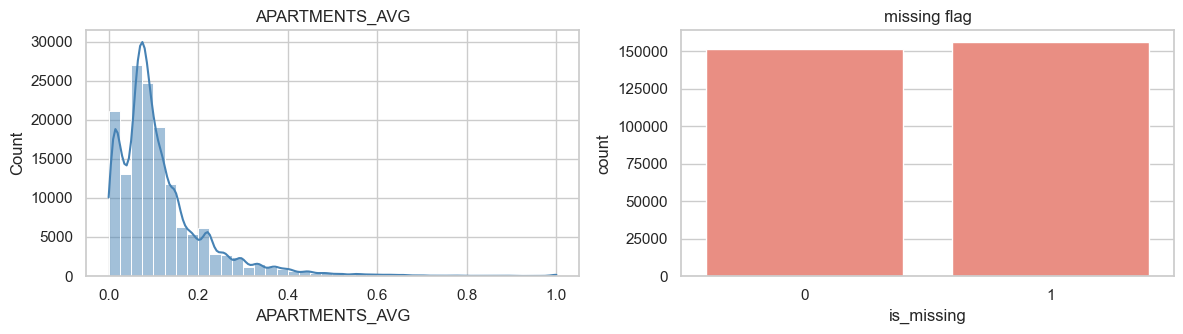

[decision] APARTMENTS_AVG: keep NaN + APARTMENTS_AVG_MISSING (50.8% missing)

=== BASEMENTAREA_AVG | missing=58.5% | dtype=float64 ===


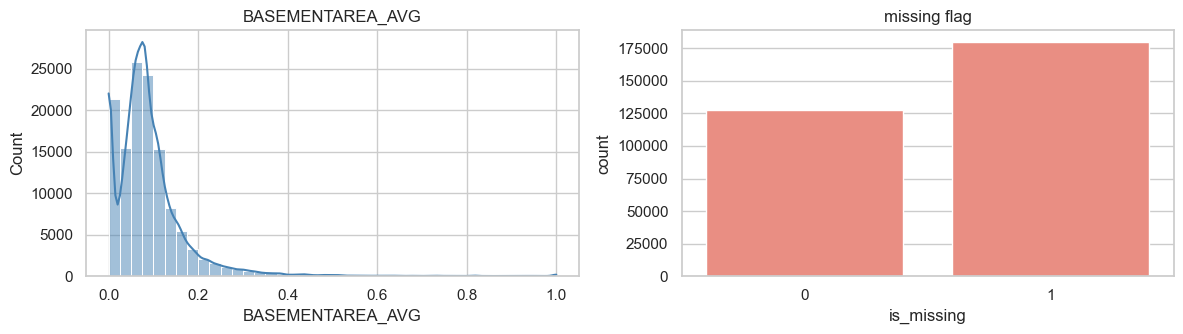

[decision] BASEMENTAREA_AVG: keep NaN + BASEMENTAREA_AVG_MISSING (58.5% missing)

=== YEARS_BEGINEXPLUATATION_AVG | missing=48.8% | dtype=float64 ===


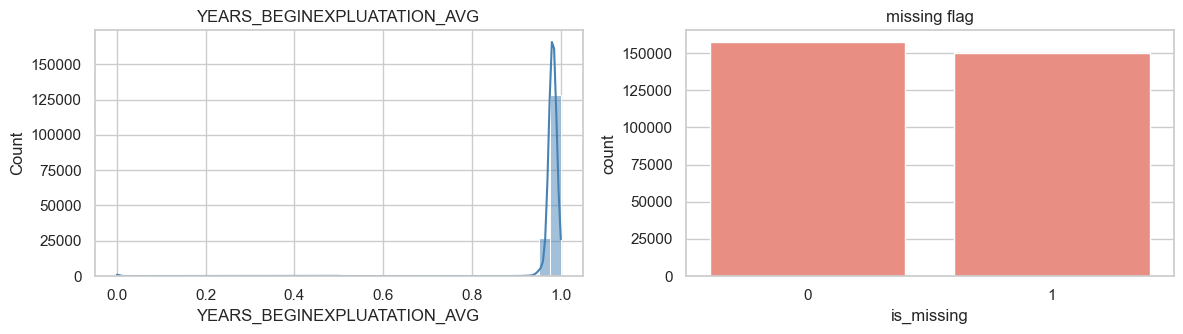

[decision] YEARS_BEGINEXPLUATATION_AVG: keep NaN + YEARS_BEGINEXPLUATATION_AVG_MISSING (48.8% missing)

=== YEARS_BUILD_AVG | missing=66.5% | dtype=float64 ===


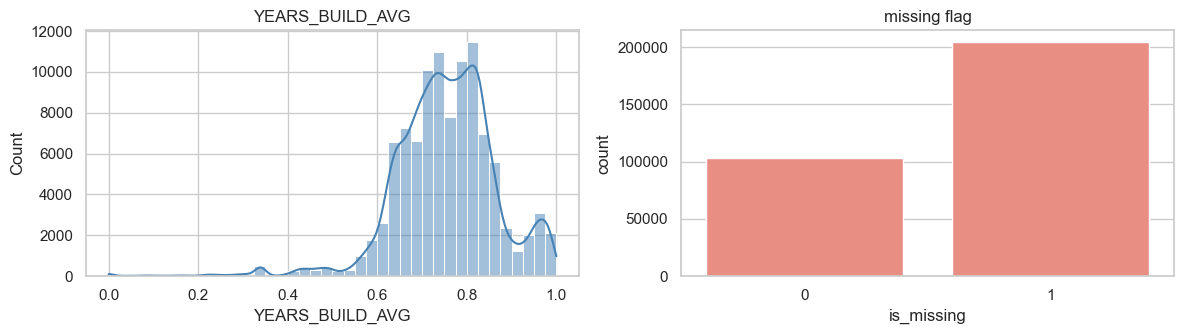

[decision] YEARS_BUILD_AVG: keep NaN + YEARS_BUILD_AVG_MISSING (66.5% missing)

=== COMMONAREA_AVG | missing=69.9% | dtype=float64 ===


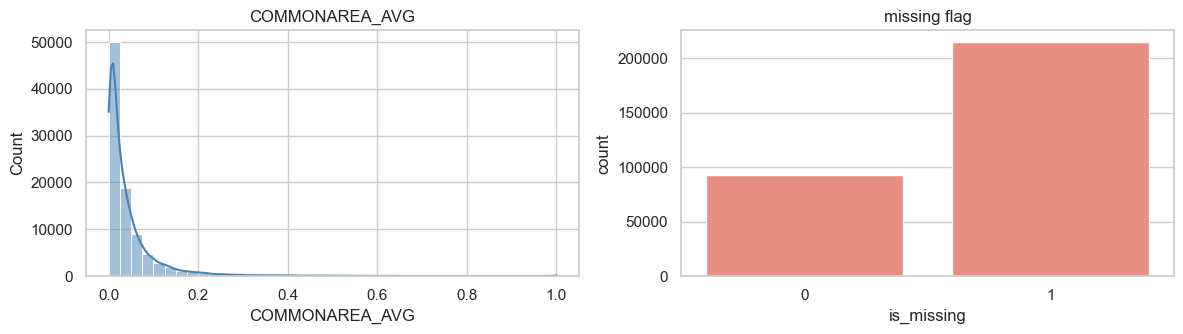

[decision] COMMONAREA_AVG: keep NaN + COMMONAREA_AVG_MISSING (69.9% missing)

=== ELEVATORS_AVG | missing=53.3% | dtype=float64 ===


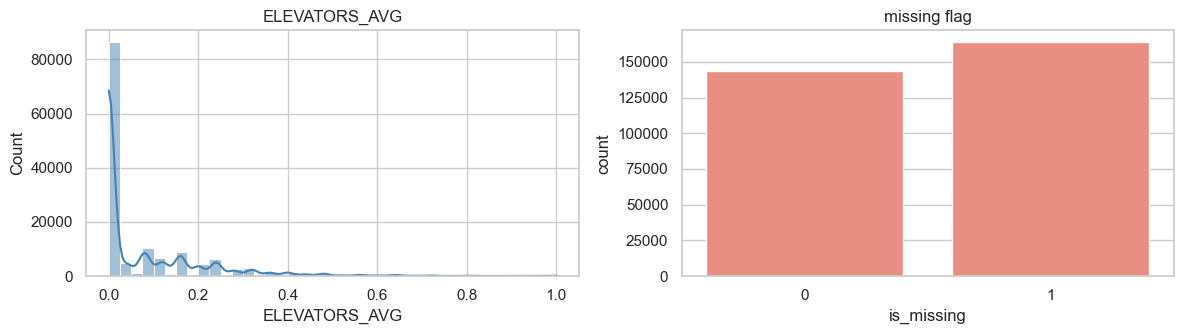

[decision] ELEVATORS_AVG: keep NaN + ELEVATORS_AVG_MISSING (53.3% missing)

=== ENTRANCES_AVG | missing=50.3% | dtype=float64 ===


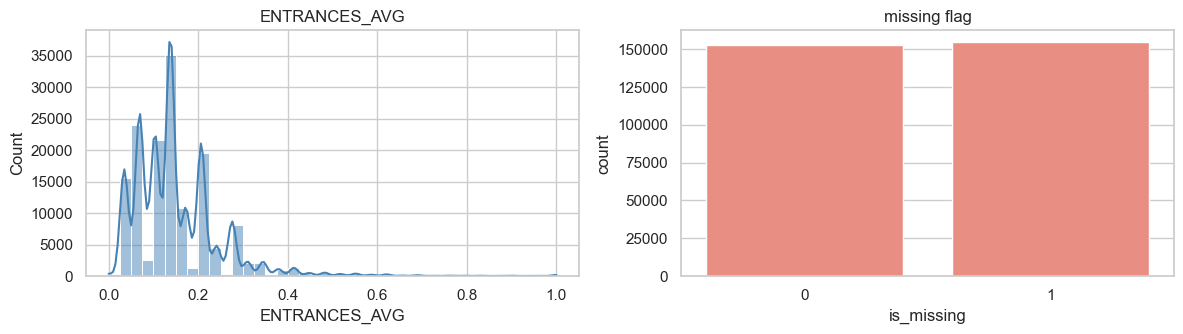

[decision] ENTRANCES_AVG: keep NaN + ENTRANCES_AVG_MISSING (50.3% missing)

=== FLOORSMAX_AVG | missing=49.8% | dtype=float64 ===


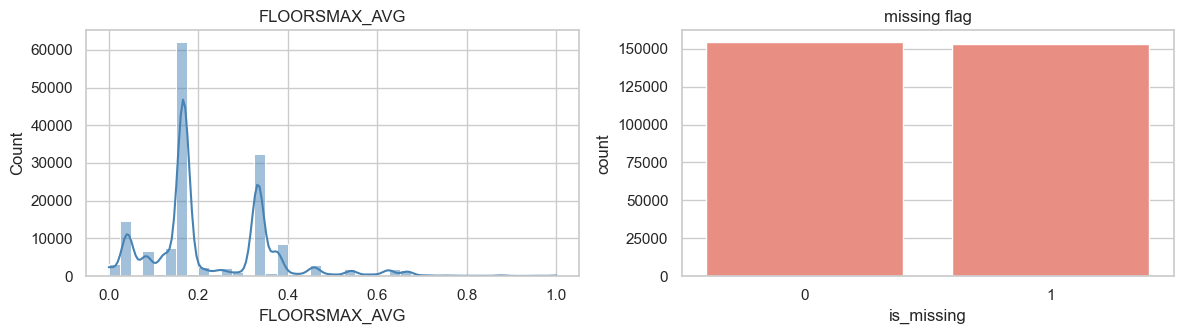

[decision] FLOORSMAX_AVG: keep NaN + FLOORSMAX_AVG_MISSING (49.8% missing)

=== FLOORSMIN_AVG | missing=67.8% | dtype=float64 ===


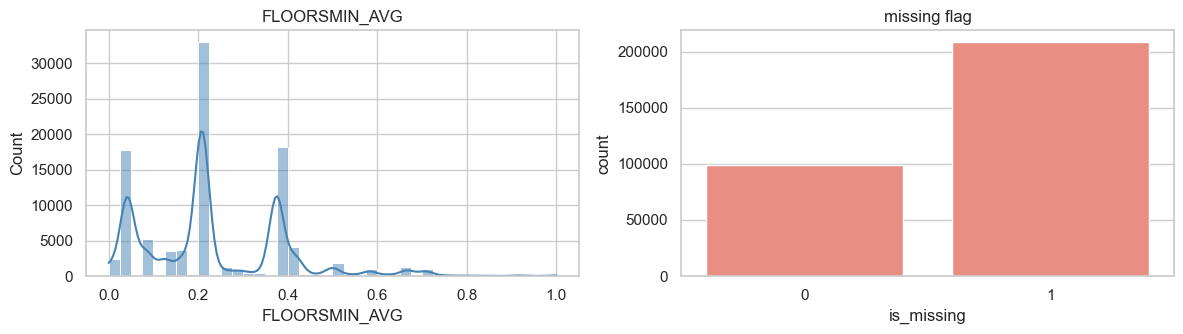

[decision] FLOORSMIN_AVG: keep NaN + FLOORSMIN_AVG_MISSING (67.8% missing)

=== LANDAREA_AVG | missing=59.4% | dtype=float64 ===


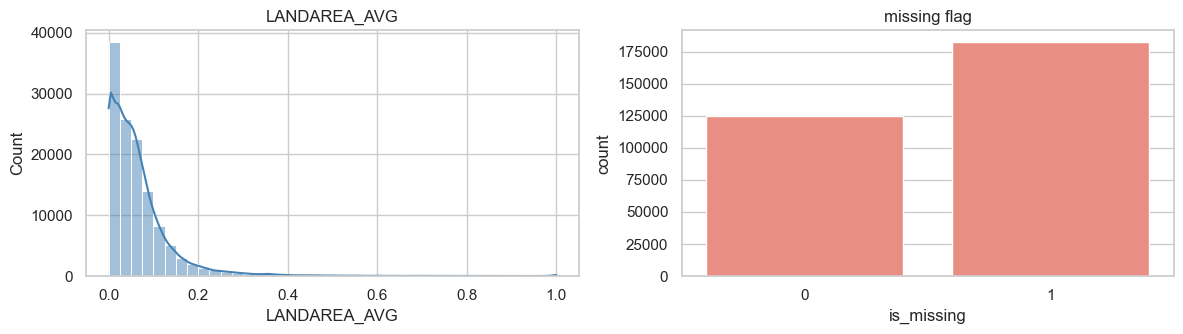

[decision] LANDAREA_AVG: keep NaN + LANDAREA_AVG_MISSING (59.4% missing)

=== LIVINGAPARTMENTS_AVG | missing=68.4% | dtype=float64 ===


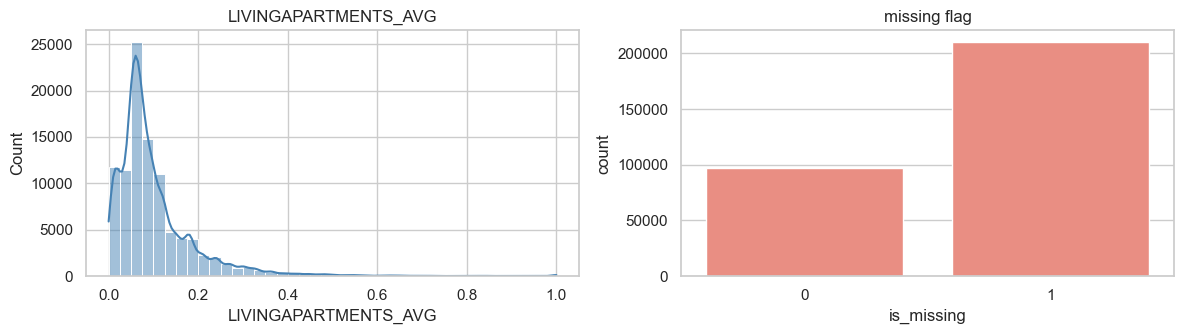

[decision] LIVINGAPARTMENTS_AVG: keep NaN + LIVINGAPARTMENTS_AVG_MISSING (68.4% missing)

=== LIVINGAREA_AVG | missing=50.2% | dtype=float64 ===


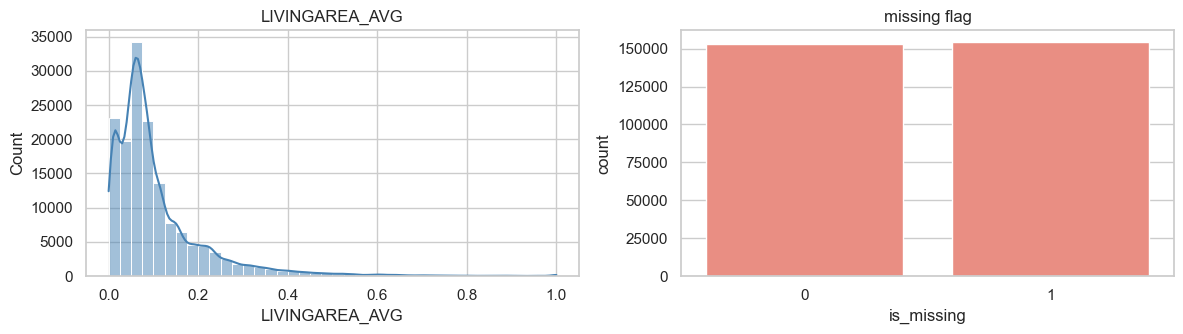

[decision] LIVINGAREA_AVG: keep NaN + LIVINGAREA_AVG_MISSING (50.2% missing)

=== NONLIVINGAPARTMENTS_AVG | missing=69.4% | dtype=float64 ===


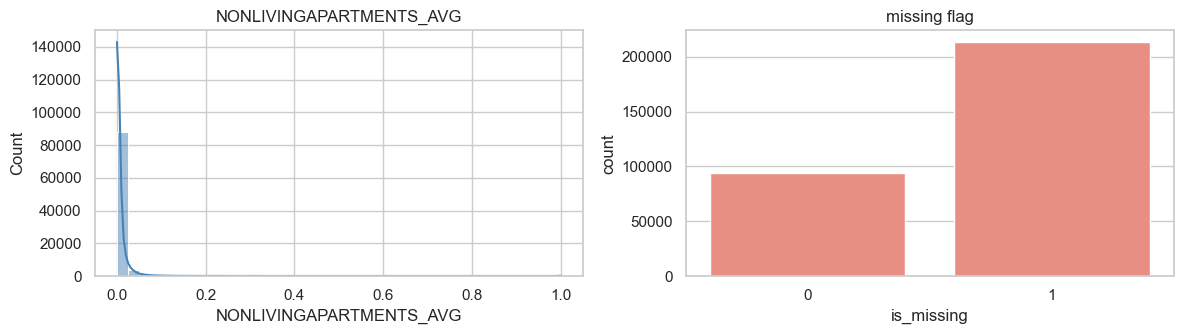

[decision] NONLIVINGAPARTMENTS_AVG: keep NaN + NONLIVINGAPARTMENTS_AVG_MISSING (69.4% missing)

=== NONLIVINGAREA_AVG | missing=55.2% | dtype=float64 ===


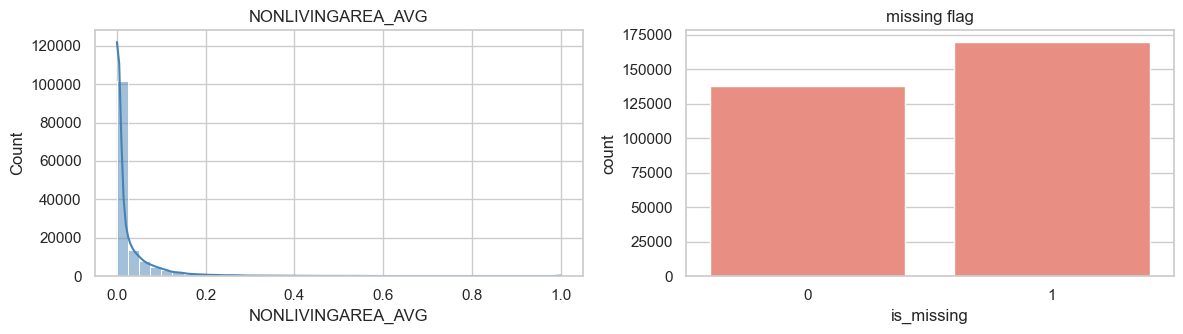

[decision] NONLIVINGAREA_AVG: keep NaN + NONLIVINGAREA_AVG_MISSING (55.2% missing)

=== APARTMENTS_MODE | missing=50.8% | dtype=float64 ===


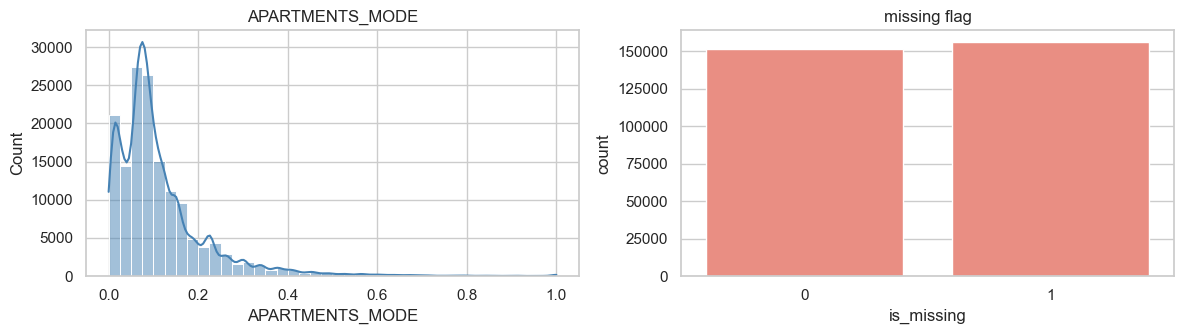

[decision] APARTMENTS_MODE: keep NaN + APARTMENTS_MODE_MISSING (50.8% missing)

=== BASEMENTAREA_MODE | missing=58.5% | dtype=float64 ===


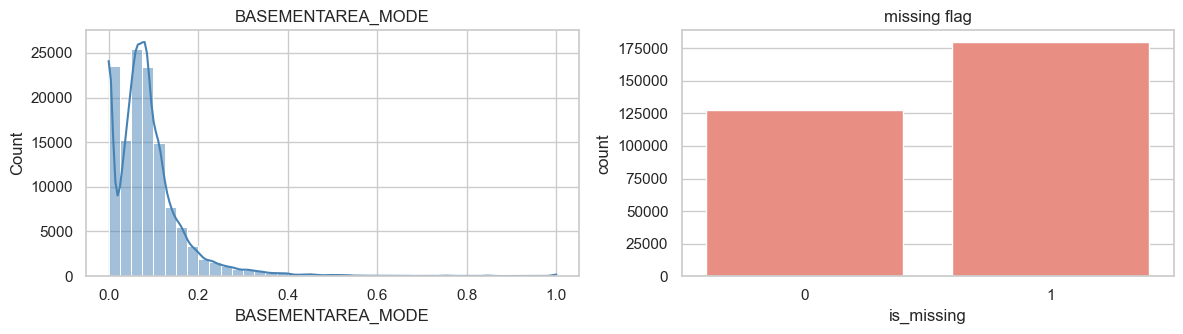

[decision] BASEMENTAREA_MODE: keep NaN + BASEMENTAREA_MODE_MISSING (58.5% missing)

=== YEARS_BEGINEXPLUATATION_MODE | missing=48.8% | dtype=float64 ===


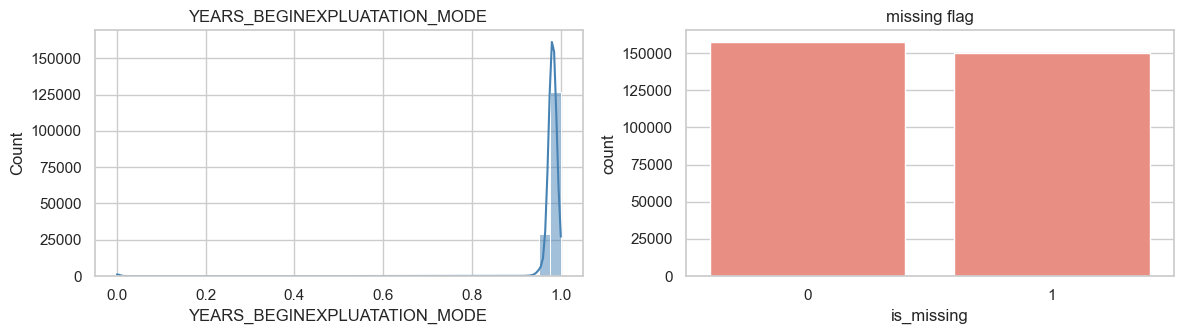

[decision] YEARS_BEGINEXPLUATATION_MODE: keep NaN + YEARS_BEGINEXPLUATATION_MODE_MISSING (48.8% missing)

=== YEARS_BUILD_MODE | missing=66.5% | dtype=float64 ===


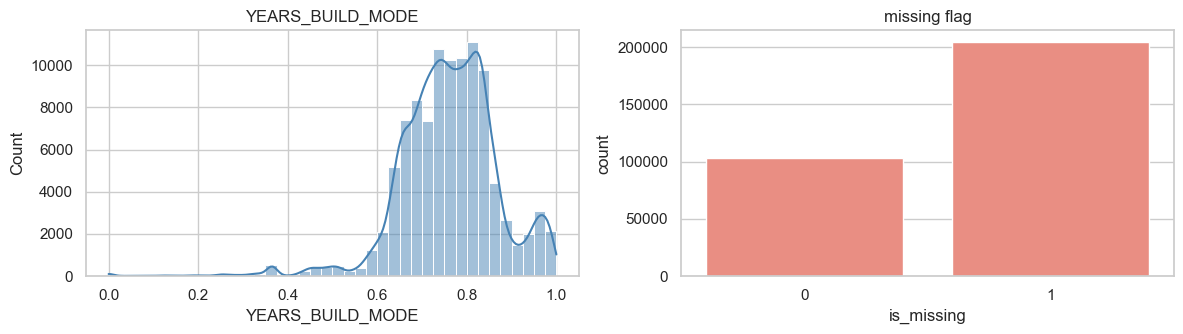

[decision] YEARS_BUILD_MODE: keep NaN + YEARS_BUILD_MODE_MISSING (66.5% missing)

=== COMMONAREA_MODE | missing=69.9% | dtype=float64 ===


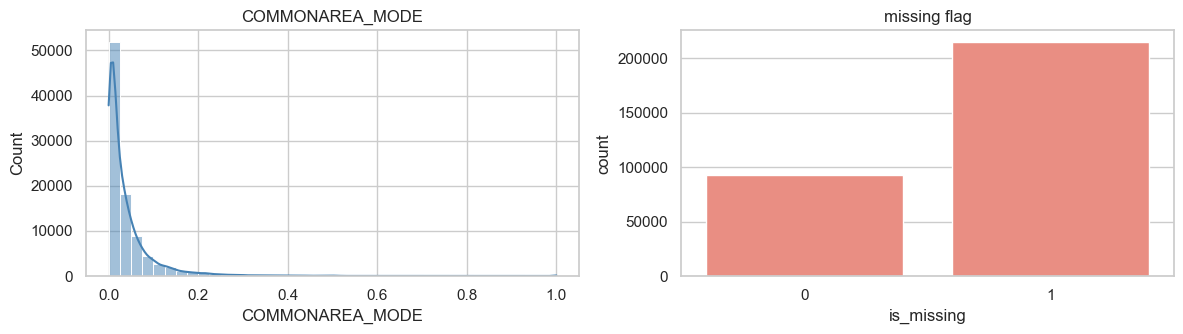

[decision] COMMONAREA_MODE: keep NaN + COMMONAREA_MODE_MISSING (69.9% missing)

=== ELEVATORS_MODE | missing=53.3% | dtype=float64 ===


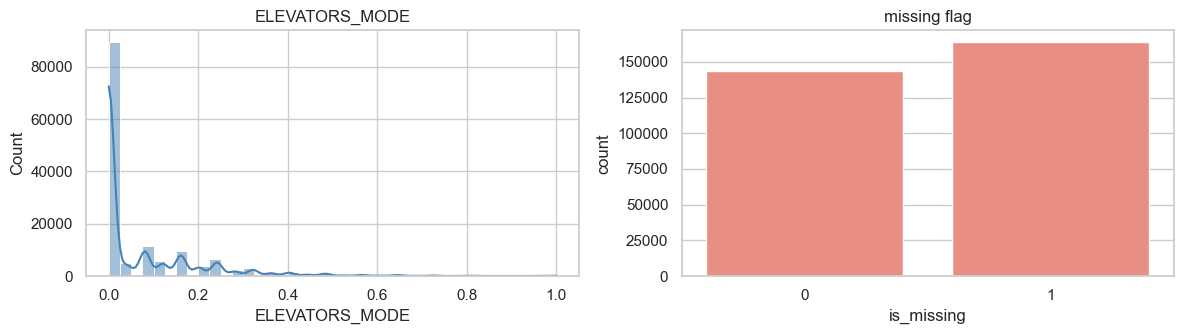

[decision] ELEVATORS_MODE: keep NaN + ELEVATORS_MODE_MISSING (53.3% missing)

=== ENTRANCES_MODE | missing=50.3% | dtype=float64 ===


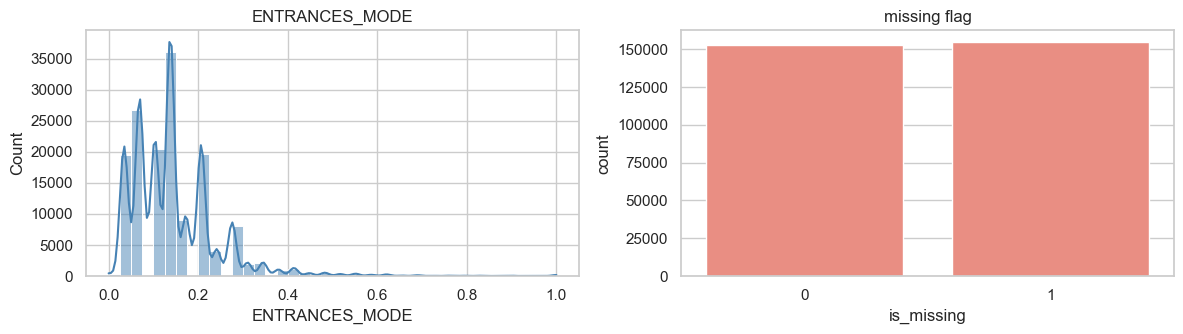

[decision] ENTRANCES_MODE: keep NaN + ENTRANCES_MODE_MISSING (50.3% missing)

=== FLOORSMAX_MODE | missing=49.8% | dtype=float64 ===


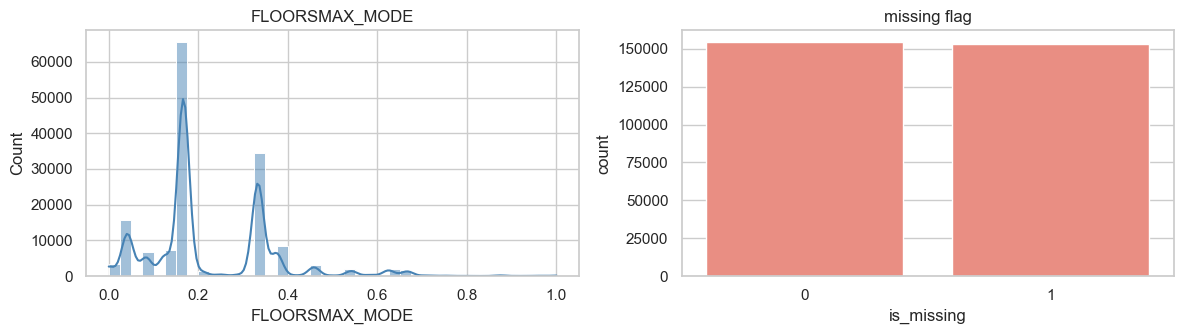

[decision] FLOORSMAX_MODE: keep NaN + FLOORSMAX_MODE_MISSING (49.8% missing)

=== FLOORSMIN_MODE | missing=67.8% | dtype=float64 ===


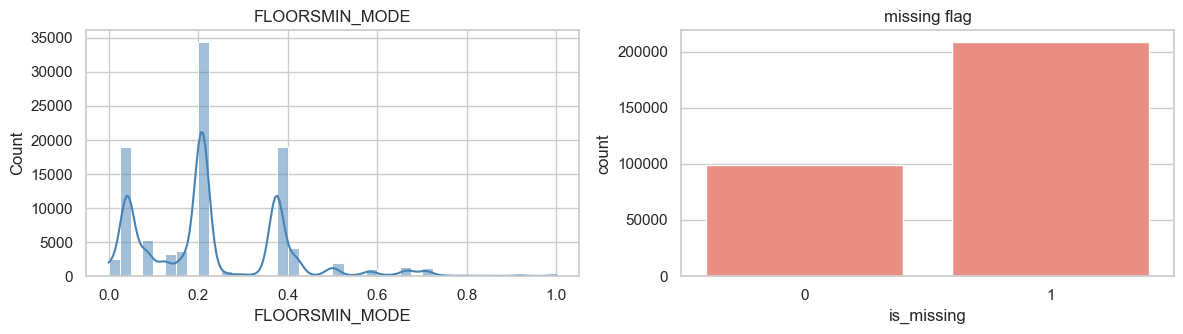

[decision] FLOORSMIN_MODE: keep NaN + FLOORSMIN_MODE_MISSING (67.8% missing)

=== LANDAREA_MODE | missing=59.4% | dtype=float64 ===


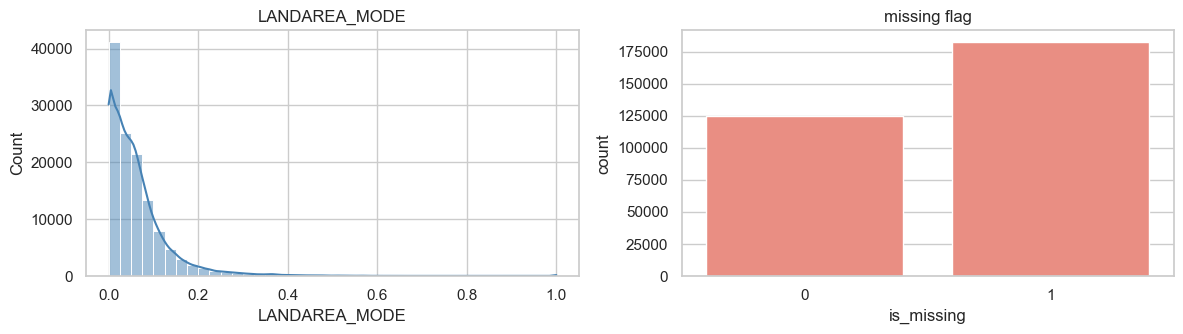

[decision] LANDAREA_MODE: keep NaN + LANDAREA_MODE_MISSING (59.4% missing)

=== LIVINGAPARTMENTS_MODE | missing=68.4% | dtype=float64 ===


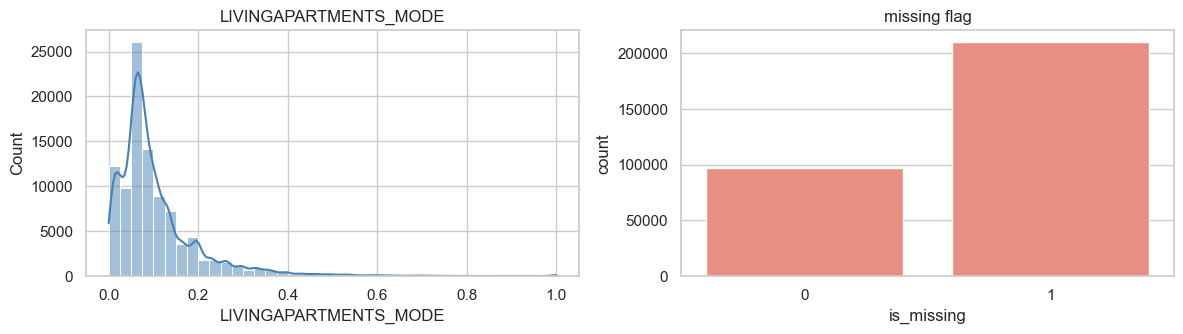

[decision] LIVINGAPARTMENTS_MODE: keep NaN + LIVINGAPARTMENTS_MODE_MISSING (68.4% missing)

=== LIVINGAREA_MODE | missing=50.2% | dtype=float64 ===


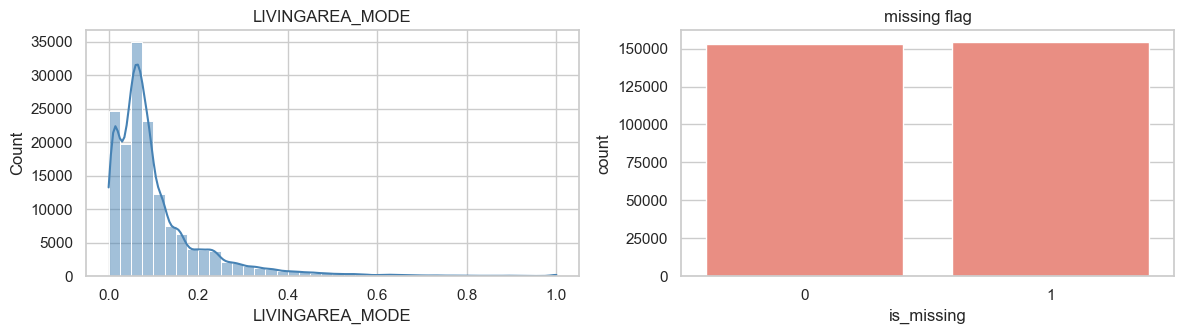

[decision] LIVINGAREA_MODE: keep NaN + LIVINGAREA_MODE_MISSING (50.2% missing)

=== NONLIVINGAPARTMENTS_MODE | missing=69.4% | dtype=float64 ===


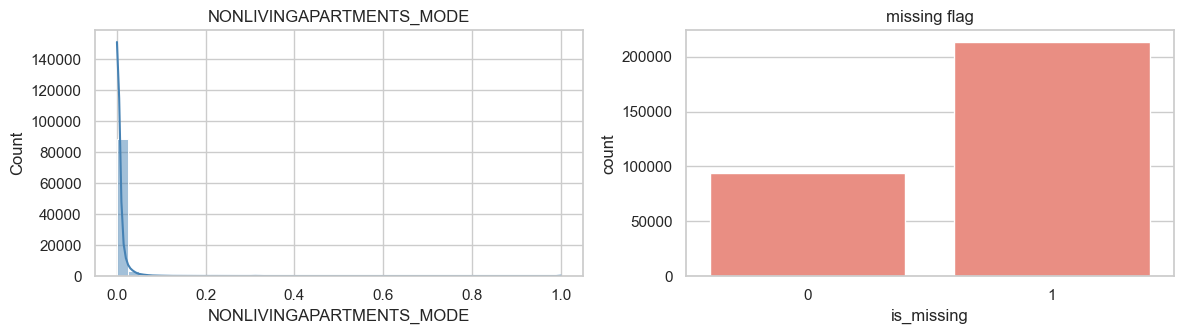

[decision] NONLIVINGAPARTMENTS_MODE: keep NaN + NONLIVINGAPARTMENTS_MODE_MISSING (69.4% missing)

=== NONLIVINGAREA_MODE | missing=55.2% | dtype=float64 ===


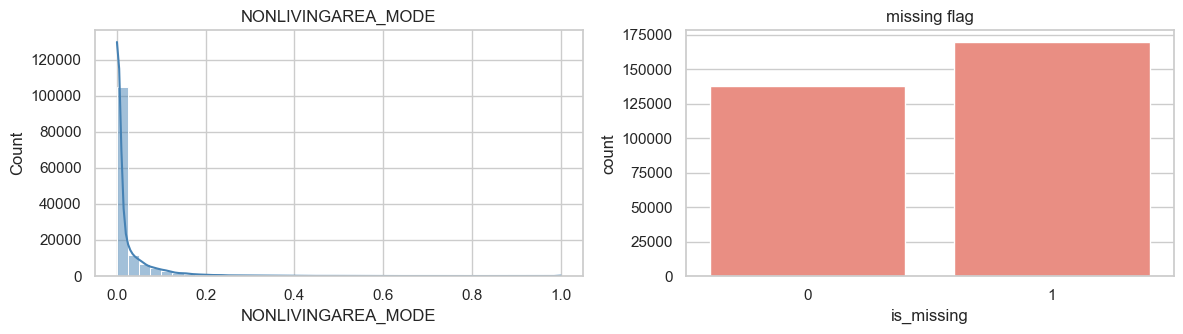

[decision] NONLIVINGAREA_MODE: keep NaN + NONLIVINGAREA_MODE_MISSING (55.2% missing)

=== APARTMENTS_MEDI | missing=50.8% | dtype=float64 ===


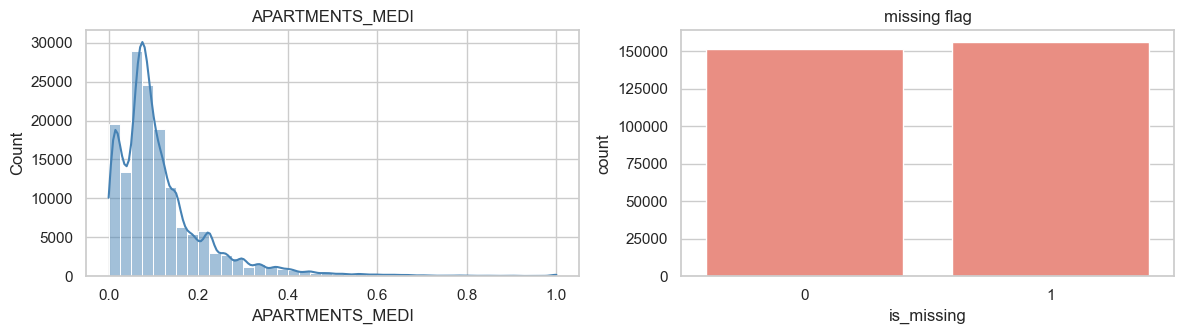

[decision] APARTMENTS_MEDI: keep NaN + APARTMENTS_MEDI_MISSING (50.8% missing)

=== BASEMENTAREA_MEDI | missing=58.5% | dtype=float64 ===


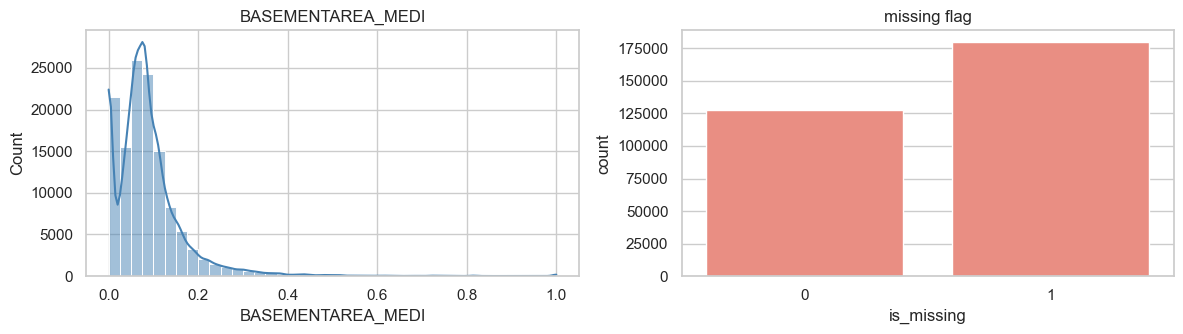

[decision] BASEMENTAREA_MEDI: keep NaN + BASEMENTAREA_MEDI_MISSING (58.5% missing)

=== YEARS_BEGINEXPLUATATION_MEDI | missing=48.8% | dtype=float64 ===


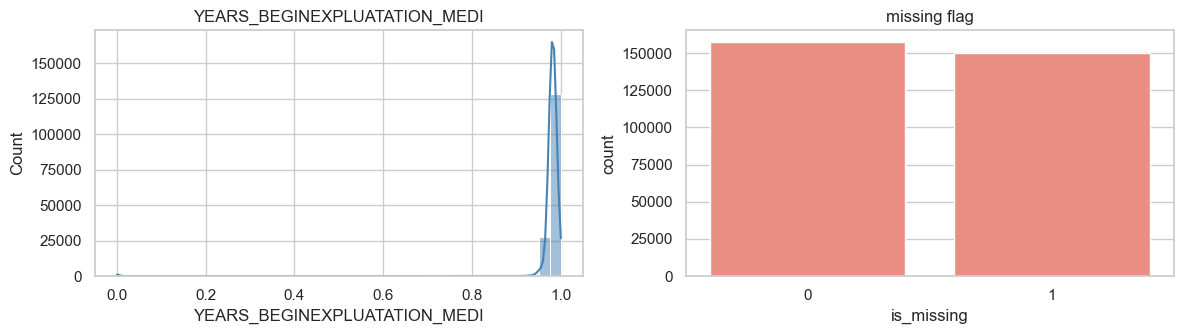

[decision] YEARS_BEGINEXPLUATATION_MEDI: keep NaN + YEARS_BEGINEXPLUATATION_MEDI_MISSING (48.8% missing)

=== YEARS_BUILD_MEDI | missing=66.5% | dtype=float64 ===


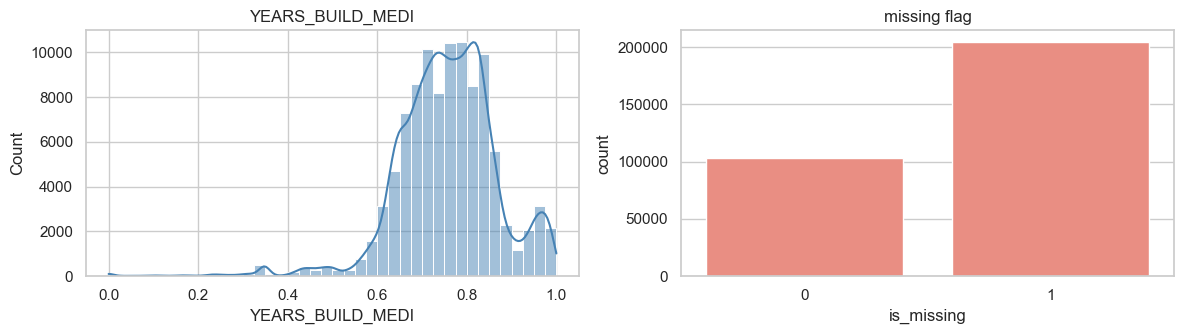

[decision] YEARS_BUILD_MEDI: keep NaN + YEARS_BUILD_MEDI_MISSING (66.5% missing)

=== COMMONAREA_MEDI | missing=69.9% | dtype=float64 ===


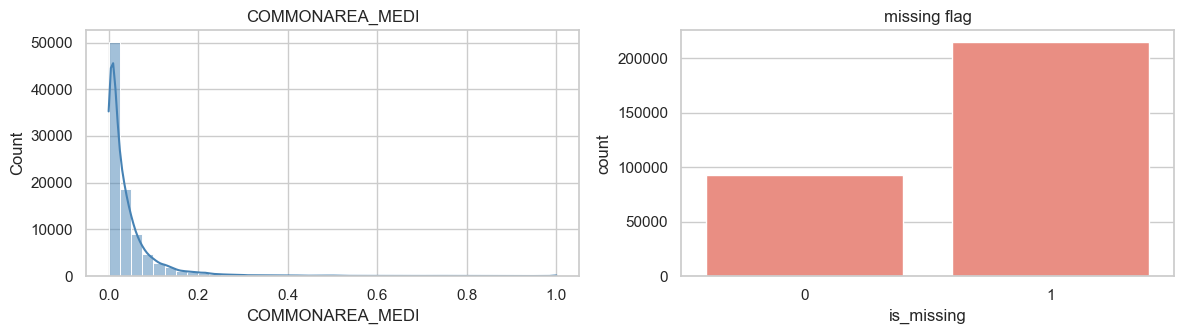

[decision] COMMONAREA_MEDI: keep NaN + COMMONAREA_MEDI_MISSING (69.9% missing)

=== ELEVATORS_MEDI | missing=53.3% | dtype=float64 ===


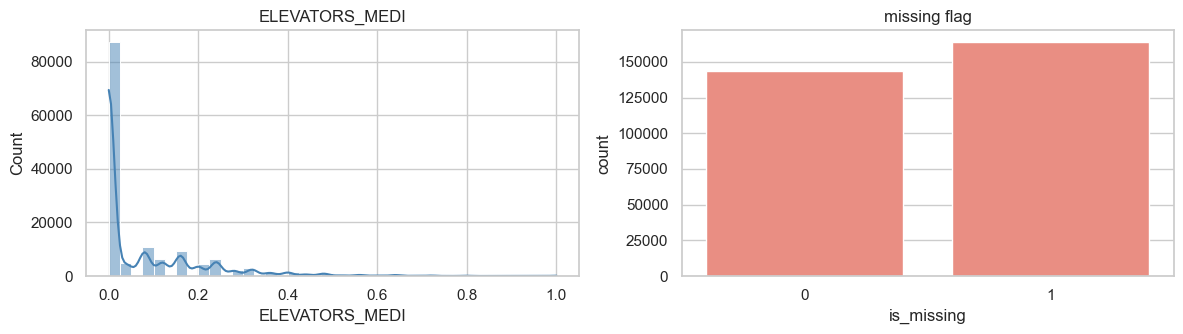

[decision] ELEVATORS_MEDI: keep NaN + ELEVATORS_MEDI_MISSING (53.3% missing)

=== ENTRANCES_MEDI | missing=50.3% | dtype=float64 ===


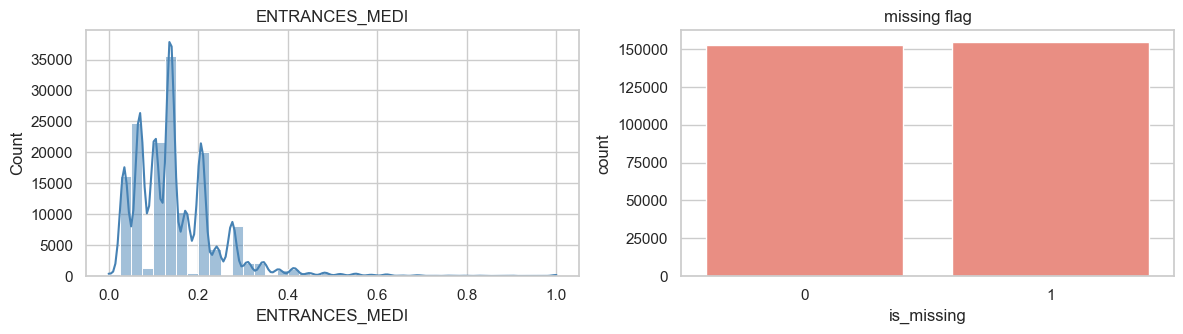

[decision] ENTRANCES_MEDI: keep NaN + ENTRANCES_MEDI_MISSING (50.3% missing)

=== FLOORSMAX_MEDI | missing=49.8% | dtype=float64 ===


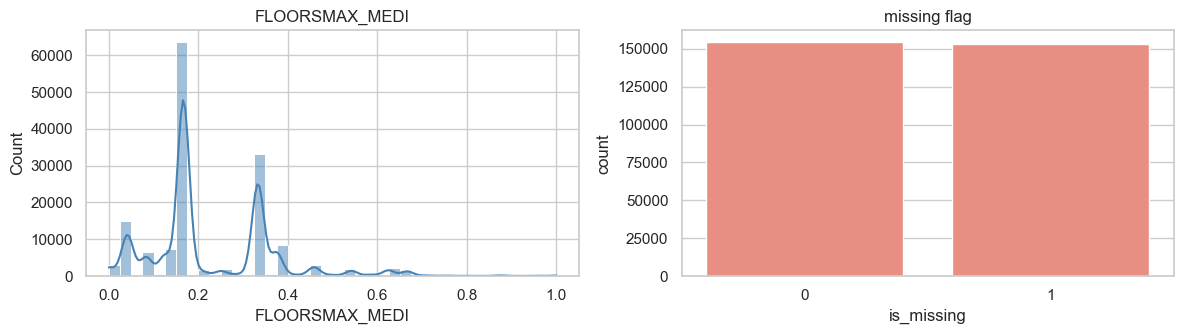

[decision] FLOORSMAX_MEDI: keep NaN + FLOORSMAX_MEDI_MISSING (49.8% missing)

=== FLOORSMIN_MEDI | missing=67.8% | dtype=float64 ===


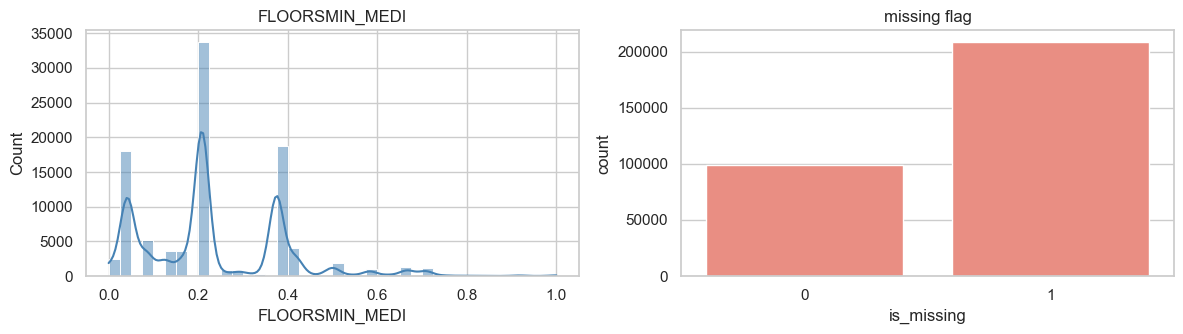

[decision] FLOORSMIN_MEDI: keep NaN + FLOORSMIN_MEDI_MISSING (67.8% missing)

=== LANDAREA_MEDI | missing=59.4% | dtype=float64 ===


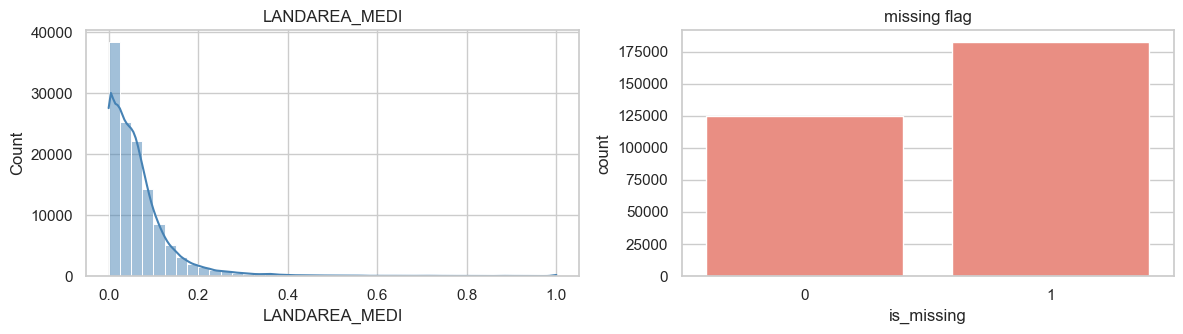

[decision] LANDAREA_MEDI: keep NaN + LANDAREA_MEDI_MISSING (59.4% missing)

=== LIVINGAPARTMENTS_MEDI | missing=68.4% | dtype=float64 ===


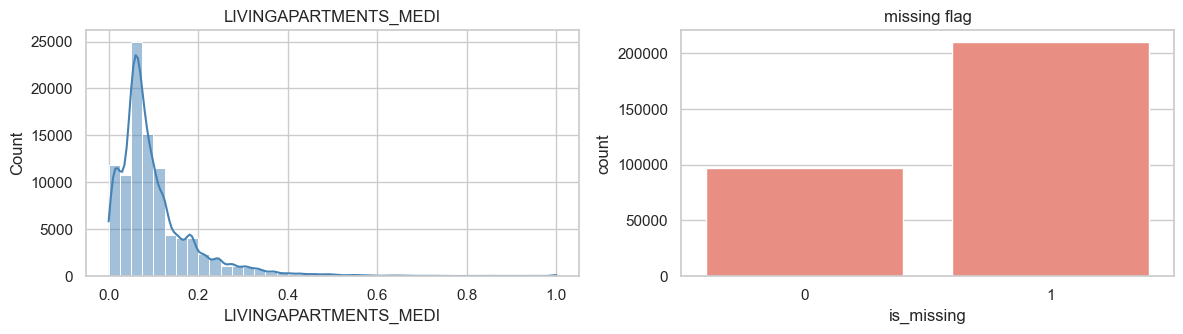

[decision] LIVINGAPARTMENTS_MEDI: keep NaN + LIVINGAPARTMENTS_MEDI_MISSING (68.4% missing)

=== LIVINGAREA_MEDI | missing=50.2% | dtype=float64 ===


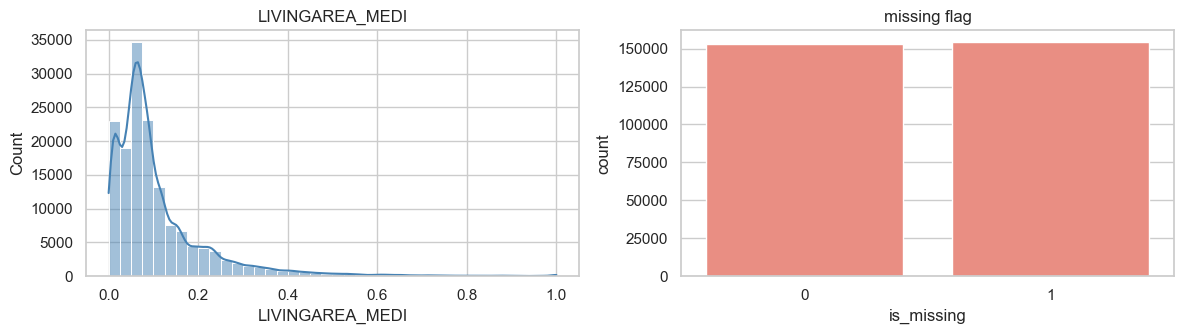

[decision] LIVINGAREA_MEDI: keep NaN + LIVINGAREA_MEDI_MISSING (50.2% missing)

=== NONLIVINGAPARTMENTS_MEDI | missing=69.4% | dtype=float64 ===


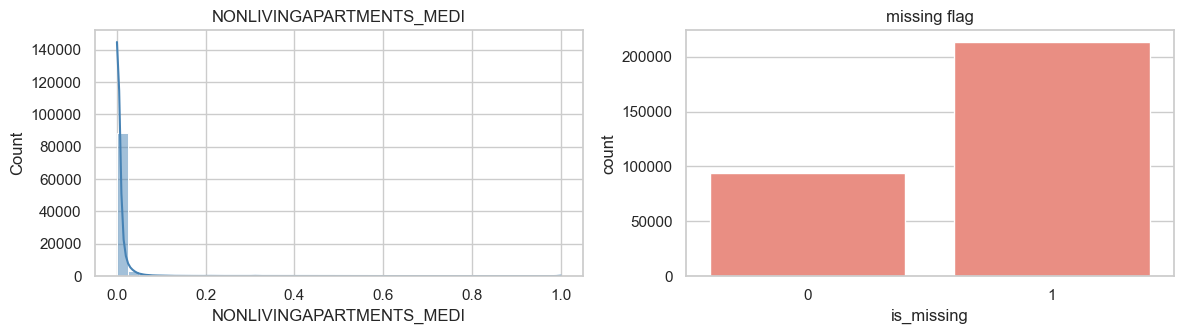

[decision] NONLIVINGAPARTMENTS_MEDI: keep NaN + NONLIVINGAPARTMENTS_MEDI_MISSING (69.4% missing)

=== NONLIVINGAREA_MEDI | missing=55.2% | dtype=float64 ===


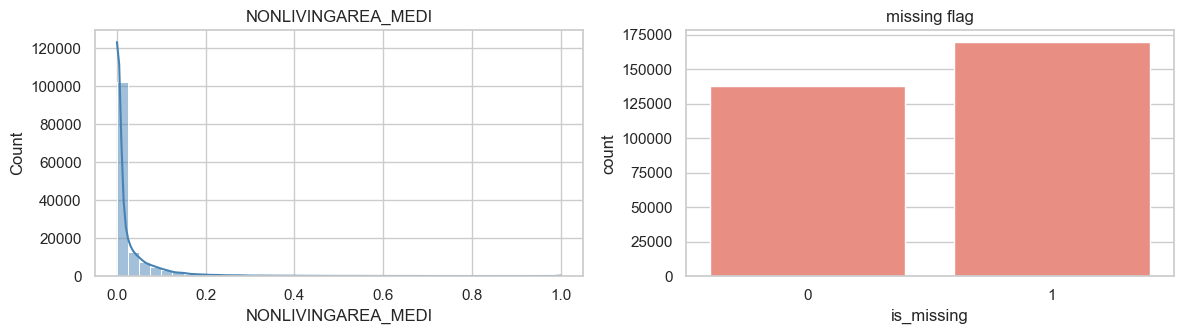

[decision] NONLIVINGAREA_MEDI: keep NaN + NONLIVINGAREA_MEDI_MISSING (55.2% missing)

=== FONDKAPREMONT_MODE | missing=68.4% | dtype=object ===


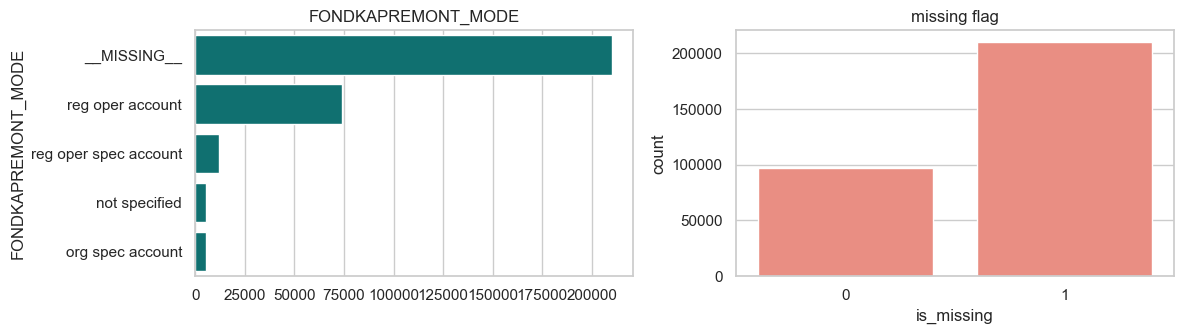

[decision] FONDKAPREMONT_MODE: fillna 'Missing' (68.4% missing categorical)

=== HOUSETYPE_MODE | missing=50.2% | dtype=object ===


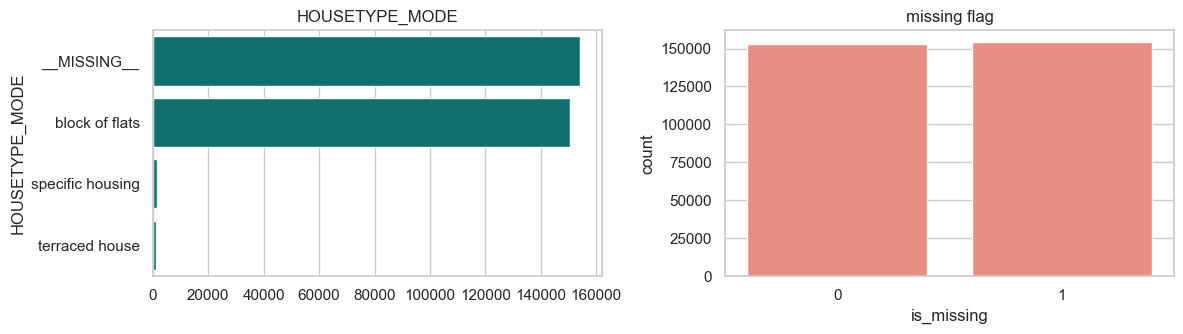

[decision] HOUSETYPE_MODE: fillna 'Missing' (50.2% missing categorical)

=== TOTALAREA_MODE | missing=48.3% | dtype=float64 ===


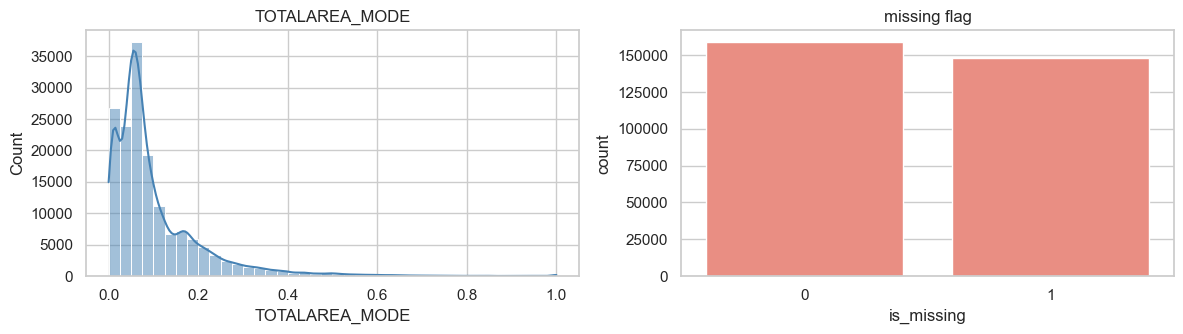

[decision] TOTALAREA_MODE: keep NaN + TOTALAREA_MODE_MISSING (48.3% missing)

=== WALLSMATERIAL_MODE | missing=50.8% | dtype=object ===


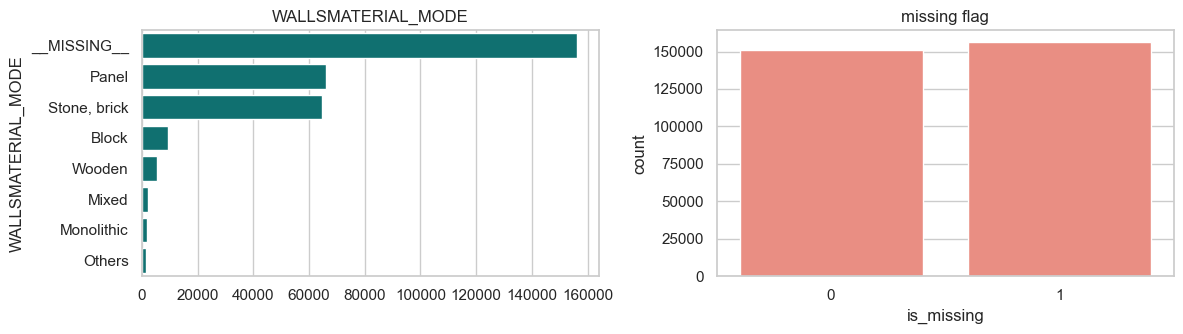

[decision] WALLSMATERIAL_MODE: fillna 'Missing' (50.8% missing categorical)

=== EMERGENCYSTATE_MODE | missing=47.4% | dtype=object ===


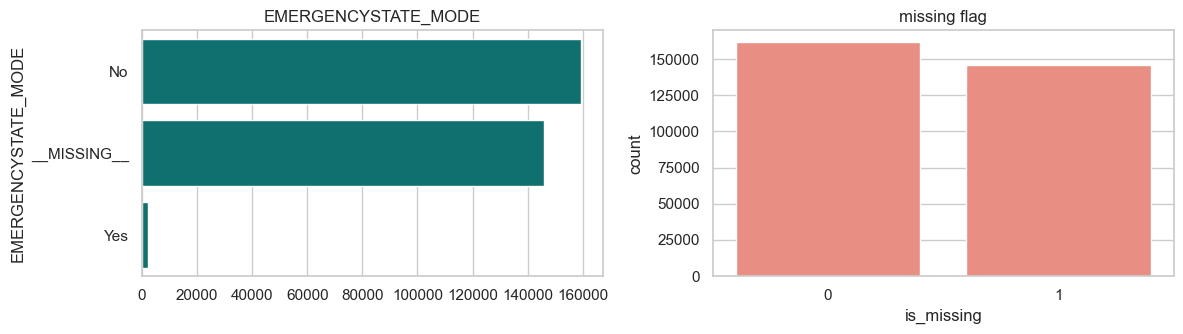

[decision] EMERGENCYSTATE_MODE: fillna 'Missing' (47.4% missing categorical)


In [31]:
housing_cols = [
    c
    for c in clean.columns
    if c.endswith("_AVG")
    or c.endswith("_MODE")
    or c.endswith("_MEDI")
    or c in {"FONDKAPREMONT_MODE", "HOUSETYPE_MODE", "WALLSMATERIAL_MODE", "EMERGENCYSTATE_MODE", "TOTALAREA_MODE"}
]
# Exclude missing-flag cols we may have created
housing_cols = [c for c in housing_cols if not c.endswith("_MISSING")]
print("housing-like columns:", len(housing_cols))

for col in housing_cols:
    s = clean[col]
    pct = 100 * s.isna().mean()
    print(f"\n=== {col} | missing={pct:.1f}% | dtype={s.dtype} ===")
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    if pd.api.types.is_numeric_dtype(s):
        plot_numeric(s, f"{col}", bins=40, ax=axes[0])
    else:
        vc = s.fillna("__MISSING__").value_counts().head(12)
        sns.barplot(x=vc.values, y=vc.index.astype(str), ax=axes[0], color="teal")
        axes[0].set_title(col)
    sns.countplot(x=s.isna().astype(int), ax=axes[1], color="salmon")
    axes[1].set_title("missing flag")
    axes[1].set_xlabel("is_missing")
    plt.tight_layout()
    plt.show()

    if pd.api.types.is_numeric_dtype(s):
        clean[f"{col}_MISSING"] = s.isna().astype("int8")
        record(col, f"{pct:.1f}% missing", f"keep NaN + {col}_MISSING")
    else:
        clean[col] = s.fillna("Missing")
        record(col, f"{pct:.1f}% missing categorical", "fillna 'Missing'")

---
## Remaining binary FLAG_* / region mismatch features

Quick one-by-one check that values are in {0,1} and not missing.

FLAG_MOBIL: unique=[0, 1] missing=0


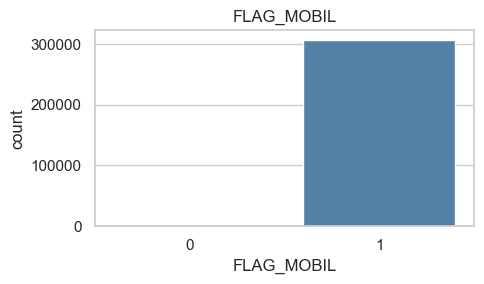

[decision] FLAG_MOBIL: keep as-is (none)
FLAG_EMP_PHONE: unique=[0, 1] missing=0


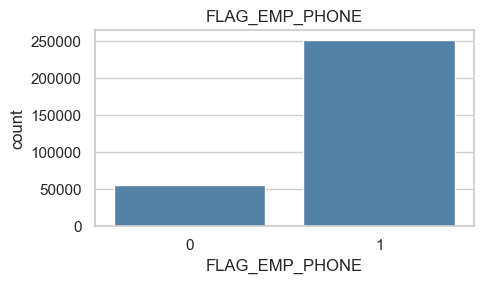

[decision] FLAG_EMP_PHONE: keep as-is (none)
FLAG_WORK_PHONE: unique=[0, 1] missing=0


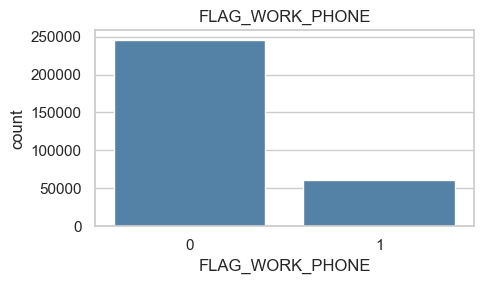

[decision] FLAG_WORK_PHONE: keep as-is (none)
FLAG_CONT_MOBILE: unique=[0, 1] missing=0


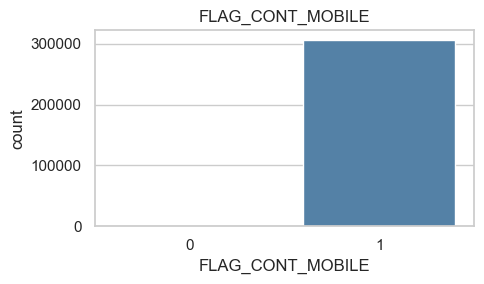

[decision] FLAG_CONT_MOBILE: keep as-is (none)
FLAG_PHONE: unique=[0, 1] missing=0


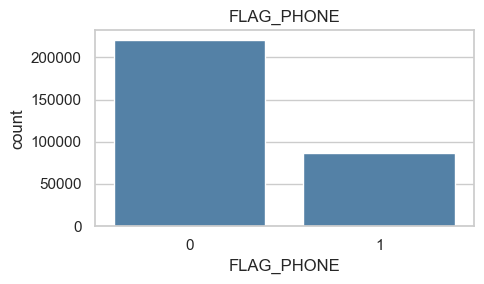

[decision] FLAG_PHONE: keep as-is (none)
FLAG_EMAIL: unique=[0, 1] missing=0


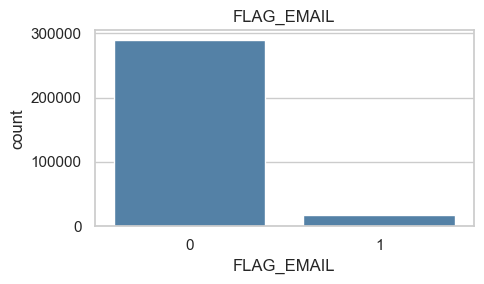

[decision] FLAG_EMAIL: keep as-is (none)
REG_REGION_NOT_LIVE_REGION: unique=[0, 1] missing=0


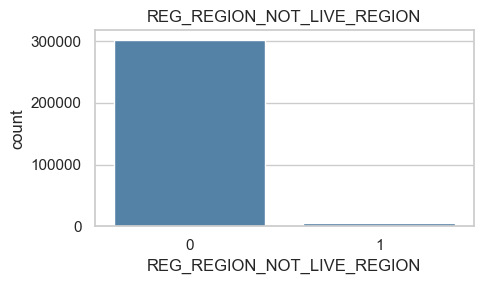

[decision] REG_REGION_NOT_LIVE_REGION: keep as-is (none)
REG_REGION_NOT_WORK_REGION: unique=[0, 1] missing=0


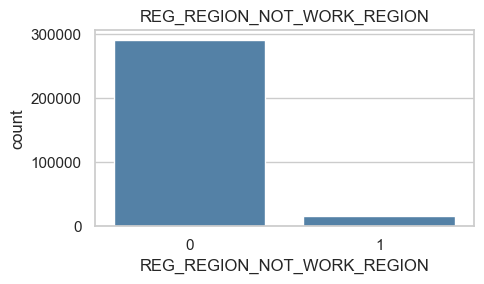

[decision] REG_REGION_NOT_WORK_REGION: keep as-is (none)
LIVE_REGION_NOT_WORK_REGION: unique=[0, 1] missing=0


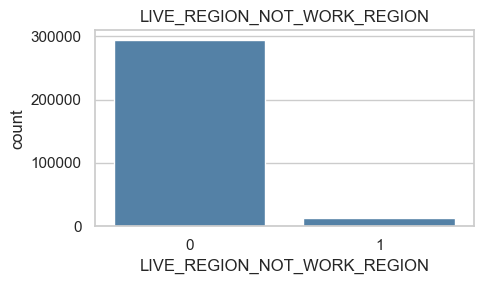

[decision] LIVE_REGION_NOT_WORK_REGION: keep as-is (none)
REG_CITY_NOT_LIVE_CITY: unique=[0, 1] missing=0


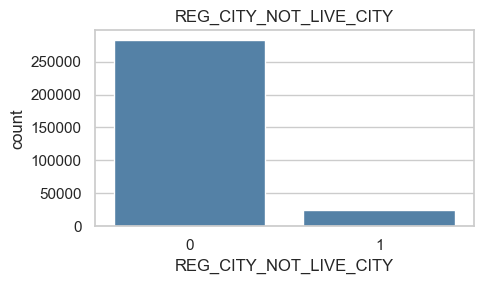

[decision] REG_CITY_NOT_LIVE_CITY: keep as-is (none)
REG_CITY_NOT_WORK_CITY: unique=[0, 1] missing=0


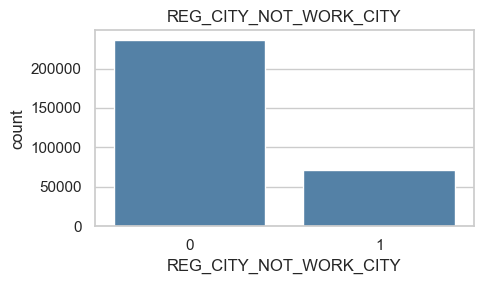

[decision] REG_CITY_NOT_WORK_CITY: keep as-is (none)
LIVE_CITY_NOT_WORK_CITY: unique=[0, 1] missing=0


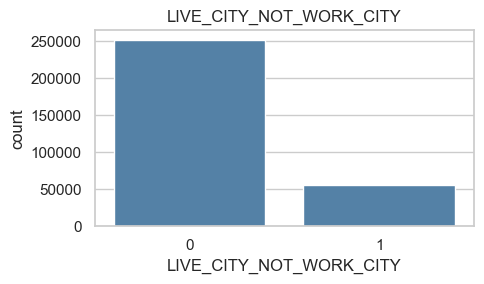

[decision] LIVE_CITY_NOT_WORK_CITY: keep as-is (none)
FLAG_DOCUMENT_2: unique=[0, 1] missing=0


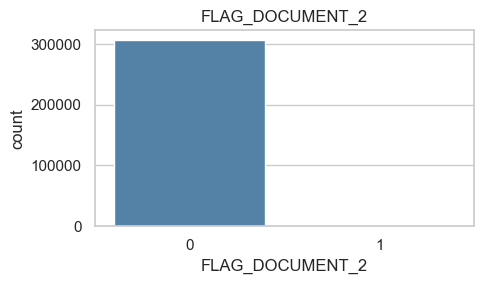

[decision] FLAG_DOCUMENT_2: keep as-is (none)
FLAG_DOCUMENT_3: unique=[0, 1] missing=0


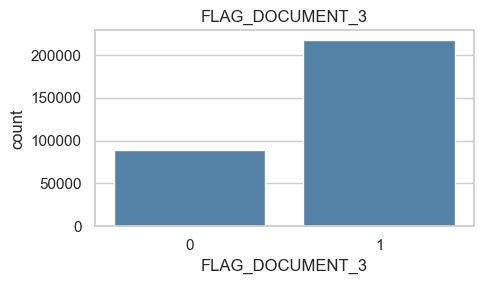

[decision] FLAG_DOCUMENT_3: keep as-is (none)
FLAG_DOCUMENT_4: unique=[0, 1] missing=0


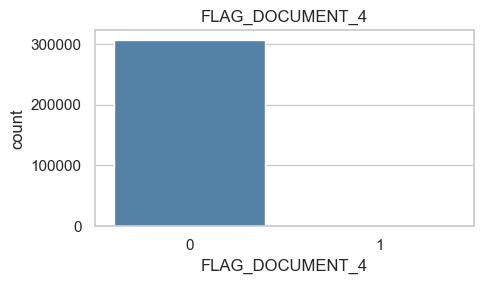

[decision] FLAG_DOCUMENT_4: keep as-is (none)
FLAG_DOCUMENT_5: unique=[0, 1] missing=0


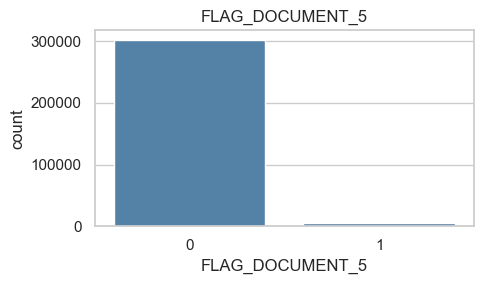

[decision] FLAG_DOCUMENT_5: keep as-is (none)
FLAG_DOCUMENT_6: unique=[0, 1] missing=0


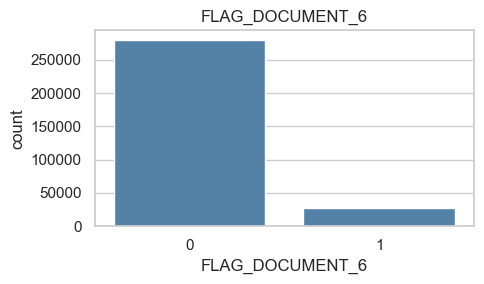

[decision] FLAG_DOCUMENT_6: keep as-is (none)
FLAG_DOCUMENT_7: unique=[0, 1] missing=0


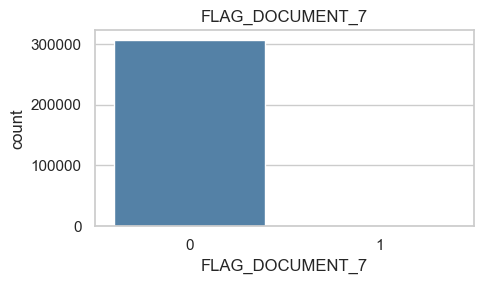

[decision] FLAG_DOCUMENT_7: keep as-is (none)
FLAG_DOCUMENT_8: unique=[0, 1] missing=0


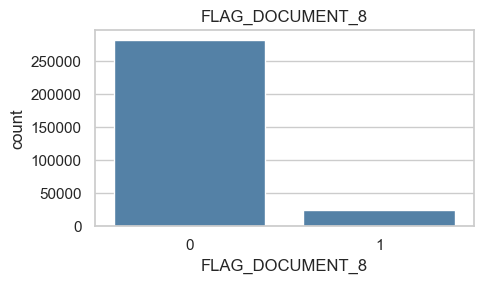

[decision] FLAG_DOCUMENT_8: keep as-is (none)
FLAG_DOCUMENT_9: unique=[0, 1] missing=0


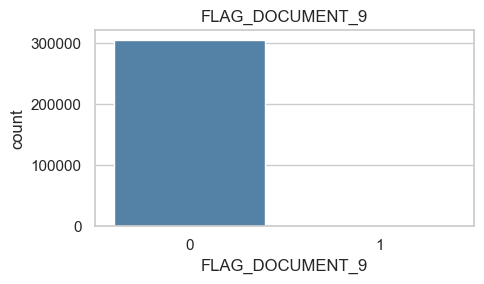

[decision] FLAG_DOCUMENT_9: keep as-is (none)
FLAG_DOCUMENT_10: unique=[0, 1] missing=0


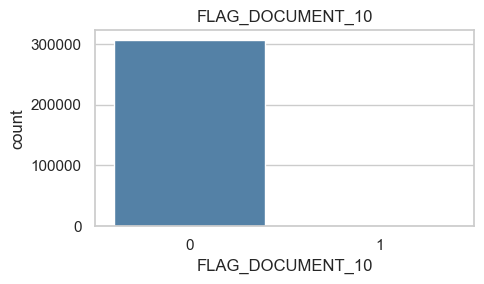

[decision] FLAG_DOCUMENT_10: keep as-is (none)
FLAG_DOCUMENT_11: unique=[0, 1] missing=0


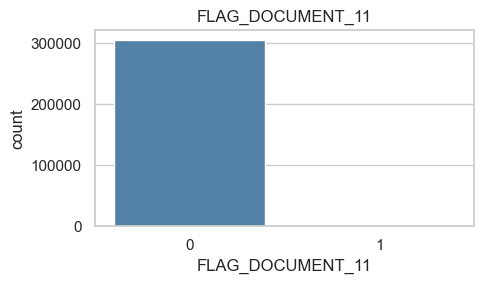

[decision] FLAG_DOCUMENT_11: keep as-is (none)
FLAG_DOCUMENT_12: unique=[0, 1] missing=0


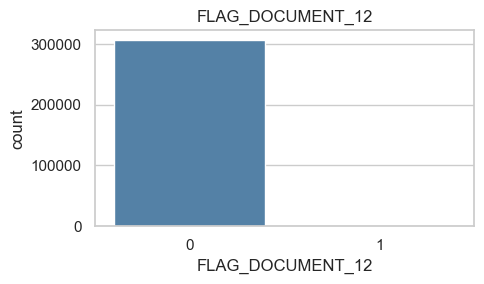

[decision] FLAG_DOCUMENT_12: keep as-is (none)
FLAG_DOCUMENT_13: unique=[0, 1] missing=0


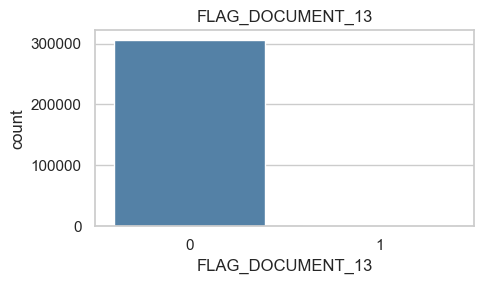

[decision] FLAG_DOCUMENT_13: keep as-is (none)
FLAG_DOCUMENT_14: unique=[0, 1] missing=0


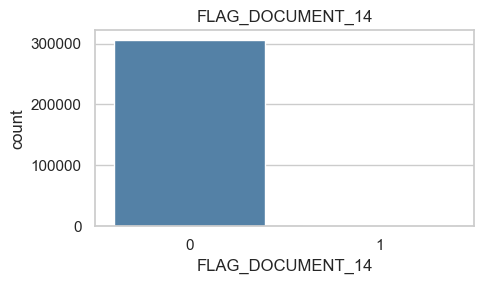

[decision] FLAG_DOCUMENT_14: keep as-is (none)
FLAG_DOCUMENT_15: unique=[0, 1] missing=0


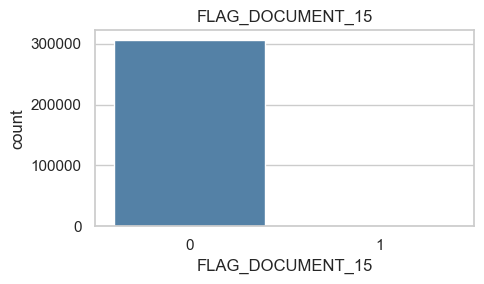

[decision] FLAG_DOCUMENT_15: keep as-is (none)
FLAG_DOCUMENT_16: unique=[0, 1] missing=0


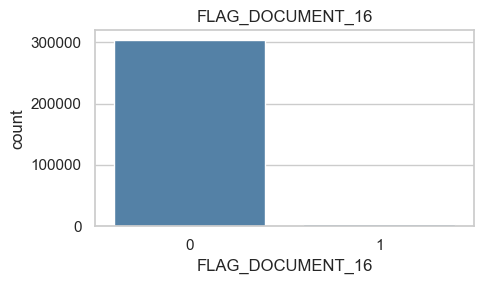

[decision] FLAG_DOCUMENT_16: keep as-is (none)
FLAG_DOCUMENT_17: unique=[0, 1] missing=0


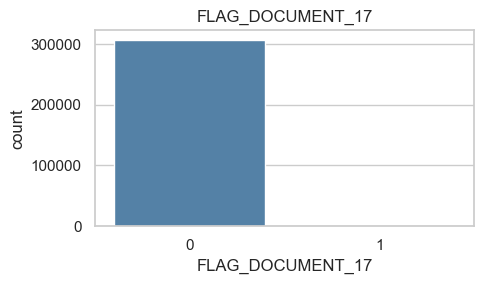

[decision] FLAG_DOCUMENT_17: keep as-is (none)
FLAG_DOCUMENT_18: unique=[0, 1] missing=0


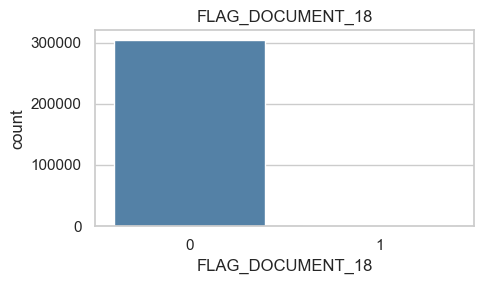

[decision] FLAG_DOCUMENT_18: keep as-is (none)
FLAG_DOCUMENT_19: unique=[0, 1] missing=0


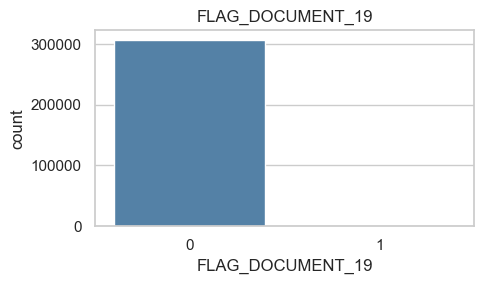

[decision] FLAG_DOCUMENT_19: keep as-is (none)
FLAG_DOCUMENT_20: unique=[0, 1] missing=0


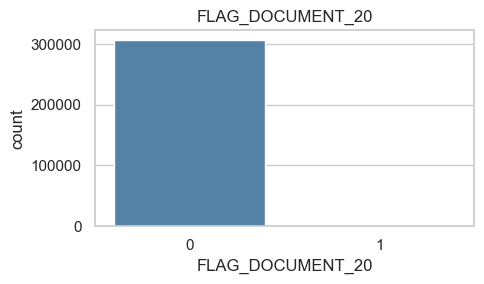

[decision] FLAG_DOCUMENT_20: keep as-is (none)
FLAG_DOCUMENT_21: unique=[0, 1] missing=0


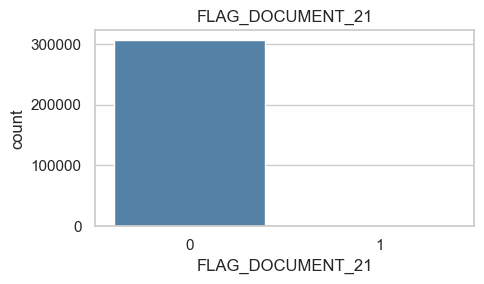

[decision] FLAG_DOCUMENT_21: keep as-is (none)


In [32]:
flag_cols = [
    c
    for c in clean.columns
    if c.startswith("FLAG_")
    or c.startswith("REG_")
    or c.startswith("LIVE_")
]
# Drop engineered missing flags from this audit list's plotting noise if needed
flag_cols = [
    c
    for c in flag_cols
    if c in df.columns  # only original flags
]

for col in flag_cols:
    s = clean[col]
    # Y/N string flags already handled separately
    if s.dtype == object:
        continue
    vals = sorted(s.dropna().unique().tolist())
    print(f"{col}: unique={vals[:10]} missing={s.isna().sum()}")
    if len(vals) <= 6:
        fig, ax = plt.subplots(figsize=(5, 3))
        sns.countplot(x=s, ax=ax, color="steelblue")
        ax.set_title(col)
        plt.tight_layout()
        plt.show()
    record(col, "none" if s.isna().sum() == 0 else "has missing", "keep as-is")

---
## Derived application ratios (sanity after cleaning amounts)

These are modelling features (prefix `app_`) previewed here.


=== app_credit_to_income ===
dtype=float64  missing=0 (0.00%)
n_unique=48696


count    307507.000000
mean          3.957593
std           2.689737
min           0.004808
25%           2.018667
50%           3.265067
75%           5.159909
max          84.736842
Name: app_credit_to_income, dtype: float64

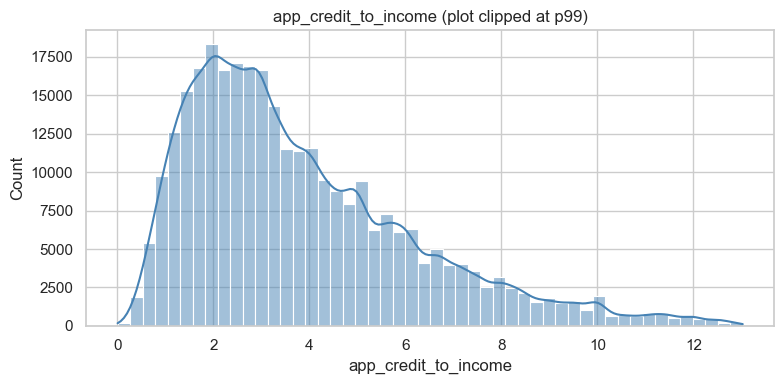

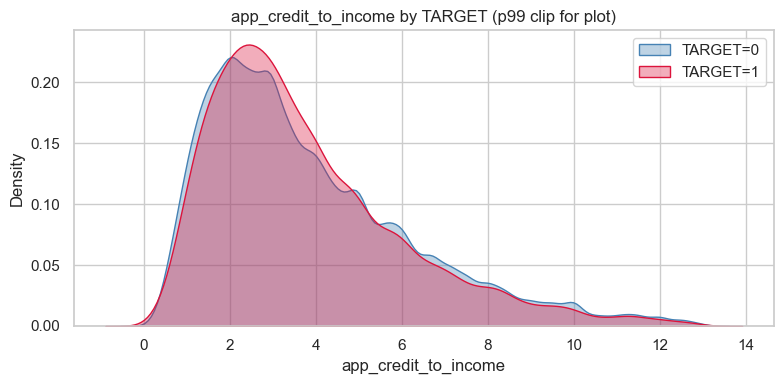

[decision] app_credit_to_income: keep; watch extreme ratios from tiny incomes (derived ratio)

=== app_annuity_to_income ===
dtype=float64  missing=12 (0.00%)
n_unique=88811


count    307495.000000
mean          0.180931
std           0.094574
min           0.000224
25%           0.114783
50%           0.162833
75%           0.229067
max           1.875965
Name: app_annuity_to_income, dtype: float64

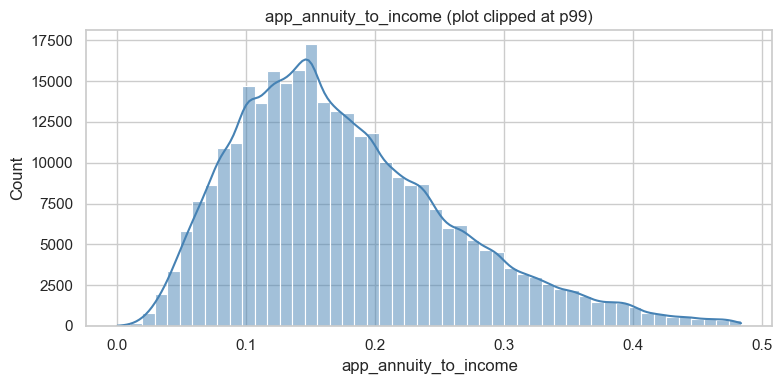

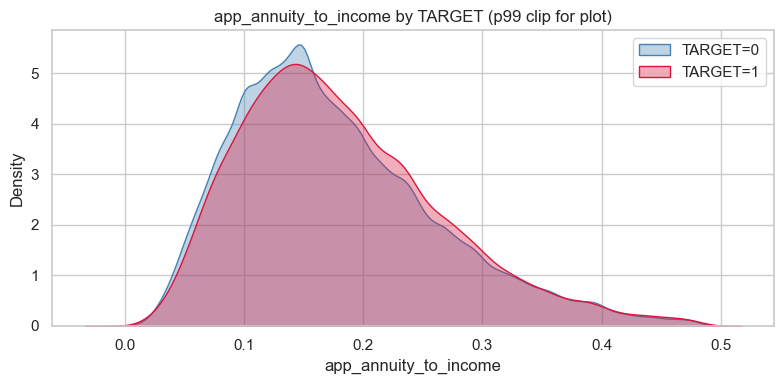

[decision] app_annuity_to_income: keep; watch extreme ratios from tiny incomes (derived ratio)

=== app_credit_to_goods ===
dtype=float64  missing=278 (0.09%)
n_unique=3064


count    307229.000000
mean          1.122994
std           0.124036
min           0.150000
25%           1.000000
50%           1.118800
75%           1.198000
max           6.000000
Name: app_credit_to_goods, dtype: float64

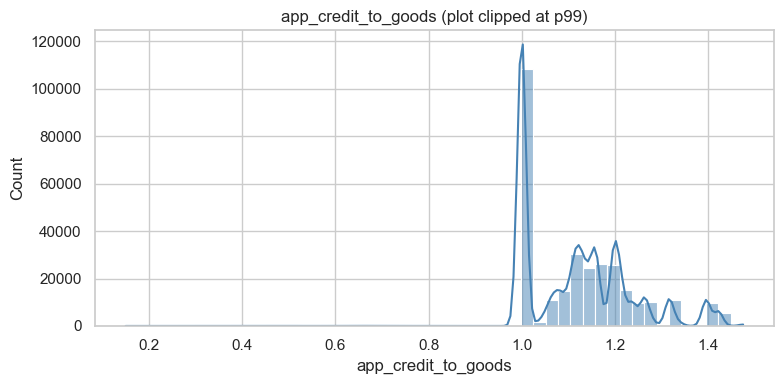

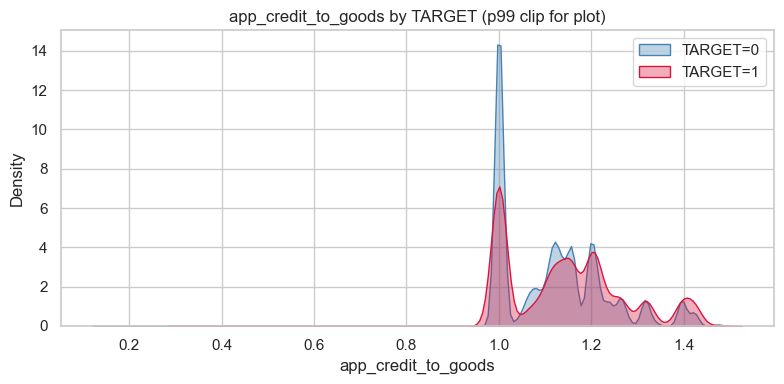

[decision] app_credit_to_goods: keep; watch extreme ratios from tiny incomes (derived ratio)


In [33]:
clean["app_credit_to_income"] = clean["AMT_CREDIT"] / clean["AMT_INCOME_TOTAL"].replace(0, np.nan)
clean["app_annuity_to_income"] = clean["AMT_ANNUITY"] / clean["AMT_INCOME_TOTAL"].replace(0, np.nan)
clean["app_credit_to_goods"] = clean["AMT_CREDIT"] / clean["AMT_GOODS_PRICE"].replace(0, np.nan)

for col in ["app_credit_to_income", "app_annuity_to_income", "app_credit_to_goods"]:
    feature_report(clean, col)
    # Cap plot at 99th pct for readability
    lo, hi = clean[col].quantile([0.0, 0.99])
    fig, ax = plt.subplots(figsize=(8, 4))
    plot_numeric(clean.loc[clean[col].between(lo, hi), col], f"{col} (plot clipped at p99)", ax=ax)
    plt.tight_layout()
    plt.show()
    plot_numeric_by_target(
        clean.loc[clean[col].between(lo, hi)],
        col,
        f"{col} by TARGET (p99 clip for plot)",
    )
    record(col, "derived ratio", "keep; watch extreme ratios from tiny incomes")

---
## Save cleaned table and decision log

In [34]:
out_parquet = PROCESSED_DATA_DIR / "application_train_clean.parquet"
out_decisions = PROCESSED_DATA_DIR / "application_cleaning_decisions.json"

clean.to_parquet(out_parquet, index=False)

payload = {
    "source": str(raw_path),
    "n_rows_raw": int(len(df)),
    "n_rows_clean": int(len(clean)),
    "n_cols_clean": int(clean.shape[1]),
    "decisions": DECISIONS,
}
out_decisions.write_text(json.dumps(payload, indent=2), encoding="ascii", errors="replace")

print("wrote", out_parquet)
print("wrote", out_decisions)
print("rows:", payload["n_rows_raw"], "->", payload["n_rows_clean"])
print("cols:", payload["n_cols_clean"])
print("n decisions:", len(DECISIONS))

decisions_df = pd.DataFrame(DECISIONS)
display(decisions_df.tail(20))
display(decisions_df["action"].value_counts().head(15))

wrote C:\Users\user\Desktop\Credit-Scoring Project\data\processed\application_train_clean.parquet
wrote C:\Users\user\Desktop\Credit-Scoring Project\data\processed\application_cleaning_decisions.json
rows: 307511 -> 307507
cols: 188
n decisions: 116


,feature,issue,action,detail
96,FLAG_DOCUMENT_5,none,keep as-is,
97,FLAG_DOCUMENT_6,none,keep as-is,
98,FLAG_DOCUMENT_7,none,keep as-is,
99,FLAG_DOCUMENT_8,none,keep as-is,
100,FLAG_DOCUMENT_9,none,keep as-is,
101,FLAG_DOCUMENT_10,none,keep as-is,
102,FLAG_DOCUMENT_11,none,keep as-is,
103,FLAG_DOCUMENT_12,none,keep as-is,
104,FLAG_DOCUMENT_13,none,keep as-is,
105,FLAG_DOCUMENT_14,none,keep as-is,


action
keep as-is                                                                         41
fillna 'Missing'                                                                    5
keep; watch extreme ratios from tiny incomes                                        3
keep raw for modelling; add log1p view for EDA; cap in preprocess on train only     1
keep raw; optional quantile cap in preprocess stage                                 1
drop rows where CODE_GENDER == XNA                                                  1
keep NaN + AMT_ANNUITY_MISSING flag; impute in train-only preprocess                1
keep raw; log1p for EDA / optional transform later                                  1
map Unknown -> Missing                                                              1
keep NaN + missing flag; impute train-only later                                    1
set anomaly to NaN; add DAYS_EMPLOYED_ANOMALY_FLAG; derive YEARS_EMPLOYED           1
derive YEARS_REGISTRATION; keep raw DAYS_REGIST

## Summary

Key cleaning actions on `application_train`:

1. Drop `CODE_GENDER == XNA` rows
2. Map `NAME_FAMILY_STATUS` Unknown and categorical missings to `Missing`
3. Replace `DAYS_EMPLOYED == 365243` with NaN + anomaly flag; add `YEARS_EMPLOYED`
4. Derive readable year features from day offsets (`AGE_YEARS`, etc.)
5. Keep numeric missings as NaN with `*_MISSING` indicators (no train leakage from imputation yet)
6. Map `ORGANIZATION_TYPE` XNA -> Missing
7. Preview `app_*` ratios for later feature SQL / modelling

Outputs:
- `data/processed/application_train_clean.parquet`
- `data/processed/application_cleaning_decisions.json`

Next: child-table quality notebook (bureau, installments, previous app) with the same before/after discipline.